# House Price Prediction
### CSE422: Artificial Intelligence, BRAC University (Spring 2024, Group 12)

**Made by Faiaz Abrar Zaman Pronoy, Sinthia Khandoker and Md. Jahirul Islam Zishan**

Given a few facts about a house (its size, age, location, rooms and garage), can a machine learn to
estimate what it will sell for? This notebook teaches several AI models to do exactly that, compares
them fairly, explains *why* they make each prediction, and ends with a working price estimator.

| | |
|---|---|
| **Task** | Supervised learning, regression (predict a number: the sale price in USD) |
| **Data** | 1,460 house sales from Ames, Iowa, 19 columns plus the price |
| **Models** | 13 learners, from a simple average to gradient boosting, a neural network and a stacked ensemble |
| **Final version** | v3. v1 was the original course submission with three models. |

**How to read this notebook:** scroll from top to bottom. Every step starts with a short note on
*what* we do and *why*, then the code, then a chart or table, then what it tells us.

**Outline**
1. Data Collection
2. Data Preprocessing
3. Exploratory Data Analysis
4. Feature Engineering and Selection
5. Model Building
6. Model Optimization
7. Model Evaluation and Explainability
8. Insights, Price Estimator and Conclusion

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, QuantileTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              StackingRegressor)
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import shap

SEED = 42
np.random.seed(SEED)

PALETTE = ['#2E5EAA', '#E4572E', '#17BEBB', '#FFC914', '#76B041', '#8E6C8A',
           '#F28F3B', '#4B4E6D', '#C8553D', '#588B8B', '#93B7BE', '#D3A588']
sns.set_theme(style='whitegrid', palette=PALETTE, font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#BBBBBB', 'grid.color': '#E6E6E6',
})
usd = mtick.FuncFormatter(lambda v, _: f'${v/1000:,.0f}k')
print('Libraries ready.')

Libraries ready.


---
## 1. Data Collection

The data comes from the Kaggle competition
[House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques).
We use 19 of its columns: lot and living area, year built, rooms, garage, location and a few
building details. The target is `SalePrice`.

| Column | Meaning |
|---|---|
| `LotArea` | Lot size in square feet |
| `Neighborhood` | Area of the city the house is in |
| `YearBuilt` | Year the house was built |
| `GrLivArea` | Living area above ground, in square feet |
| `FullBath`, `BedroomAbvGr`, `KitchenAbvGr` | Bathrooms, bedrooms and kitchens |
| `Fireplaces`, `GarageCars` | Fireplaces, and how many cars the garage holds |
| `BldgType`, `HouseStyle`, `Foundation`, `RoofStyle` | Type and build of the house |
| `SaleCondition` | Normal sale, family sale, new build and so on |
| **`SalePrice`** | **What we predict:** the price the house sold for |

In [2]:
import os
CSV = 'data/house_prices.csv'
if not os.path.exists(CSV):
    CSV = 'https://raw.githubusercontent.com/FaiazPronoy/House_Price_Prediction/main/data/house_prices.csv'

raw = pd.read_csv(CSV)
print(f'{raw.shape[0]:,} houses and {raw.shape[1]} columns')
raw.head(8)

1,460 houses and 20 columns


,Id,LotArea,Street,Alley,Utilities,Neighborhood,BldgType,HouseStyle,YearBuilt,RoofStyle,Foundation,Electrical,GrLivArea,FullBath,BedroomAbvGr,KitchenAbvGr,Fireplaces,GarageCars,SaleCondition,SalePrice
0,1,8450.0,Pave,NaN,AllPub,CollgCr,1Fam,2Story,2003.0,Gable,PConc,SBrkr,1710.0,2.0,3.0,1.0,0.0,2.0,Normal,208500
1,2,9600.0,Pave,NaN,AllPub,Veenker,1Fam,1Story,1976.0,Gable,CBlock,SBrkr,1262.0,2.0,3.0,1.0,1.0,2.0,Normal,181500
2,3,11250.0,Pave,NaN,AllPub,CollgCr,1Fam,2Story,2001.0,Gable,PConc,SBrkr,1786.0,2.0,3.0,1.0,1.0,2.0,Normal,223500
3,4,9550.0,Pave,NaN,AllPub,Crawfor,1Fam,2Story,1915.0,Gable,BrkTil,SBrkr,1717.0,1.0,3.0,1.0,1.0,3.0,Abnorml,140000
4,5,14260.0,Pave,NaN,AllPub,NoRidge,1Fam,2Story,2000.0,Gable,PConc,SBrkr,2198.0,2.0,4.0,1.0,1.0,3.0,Normal,250000
5,6,14115.0,Pave,NaN,AllPub,Mitchel,1Fam,1.5Fin,1993.0,Gable,Wood,SBrkr,1362.0,1.0,1.0,1.0,0.0,2.0,Normal,143000
6,7,10084.0,Pave,NaN,AllPub,Somerst,1Fam,1Story,2004.0,Gable,PConc,SBrkr,1694.0,2.0,3.0,1.0,1.0,2.0,Normal,307000
7,8,10382.0,Pave,NaN,AllPub,NWAmes,1Fam,2Story,1973.0,Gable,CBlock,SBrkr,2090.0,2.0,3.0,1.0,2.0,2.0,Normal,200000


In [3]:
profile = pd.DataFrame({
    'type': raw.dtypes.astype(str).str.replace('object', 'text').str.replace('str', 'text'),
    'missing': raw.isna().sum(),
    'missing %': (raw.isna().mean() * 100).round(1),
    'unique values': raw.nunique(),
    'example': raw.iloc[0],
})
profile.style.background_gradient(subset=['missing %'], cmap='Reds').format({'missing %': '{:.1f}'})

,type,missing,missing %,unique values,example
Id,int64,0,0.0,1460,1
LotArea,float64,1,0.1,1073,8450.000000
Street,text,0,0.0,2,Pave
Alley,text,1369,93.8,2,nan
Utilities,text,12,0.8,2,AllPub
Neighborhood,text,7,0.5,25,CollgCr
BldgType,text,11,0.8,5,1Fam
HouseStyle,text,6,0.4,8,2Story
YearBuilt,float64,7,0.5,112,2003.000000
RoofStyle,text,6,0.4,6,Gable


---
## 2. Data Preprocessing

Real data is messy. Before any model can learn from it we:

1. look at what is **missing**,
2. **drop** columns that cannot help (`Id`) or are mostly empty (`Alley`),
3. remove **duplicate** rows,
4. check for **impossible values** (negative areas, a house with no rooms),
5. look at **outliers**, and decide how to handle them.

Filling missing values and encoding text columns happens *inside* each model's pipeline in Section 5,
so the test set never leaks into training.

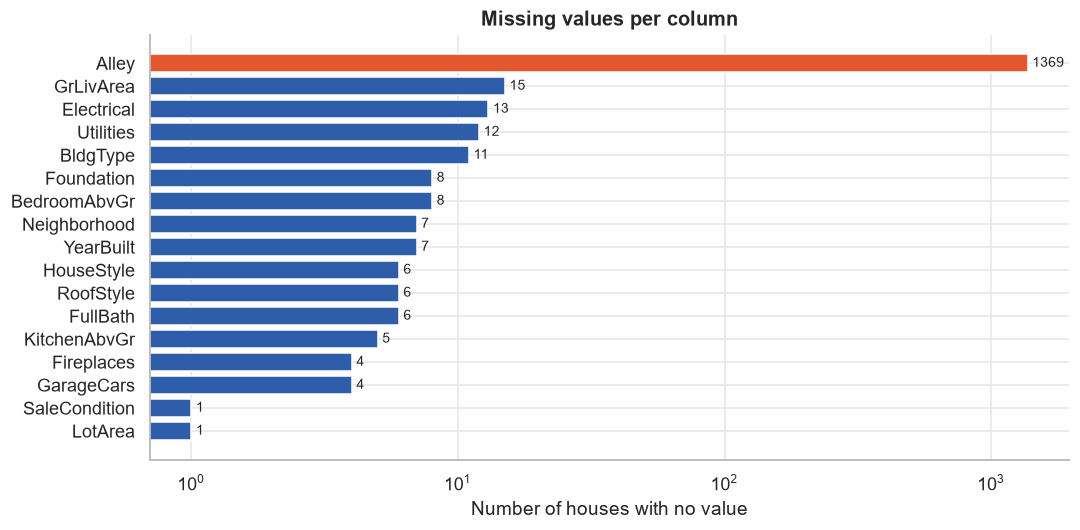

'Alley' is empty for 94% of houses, so it is dropped.
Every other column misses at most 15 values, which we fill later.


In [4]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing.index, missing.values,
               color=[PALETTE[1] if v > 100 else PALETTE[0] for v in missing.values])
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title('Missing values per column')
ax.set_xlabel('Number of houses with no value')
ax.set_xscale('log')
plt.tight_layout(); plt.show()

print(f"'Alley' is empty for {raw['Alley'].isna().mean():.0%} of houses, so it is dropped.")
print(f'Every other column misses at most {missing.drop("Alley").max()} values, which we fill later.')

In [5]:
housing = raw.drop(columns=['Id', 'Alley'])

dupes = housing.duplicated().sum()
housing = housing.drop_duplicates().reset_index(drop=True)
print(f'Duplicate rows removed: {dupes}')

numeric = ['LotArea', 'YearBuilt', 'GrLivArea', 'FullBath', 'BedroomAbvGr',
           'KitchenAbvGr', 'Fireplaces', 'GarageCars']
negatives = (housing[numeric + ['SalePrice']] < 0).sum()
print(f'Negative values found: {int(negatives.sum())}')
print(f'Shape after cleaning: {housing.shape}')

Duplicate rows removed: 1
Negative values found: 0
Shape after cleaning: (1459, 18)


### Outliers

An outlier is a house that is very unlike the rest. Two kinds matter here:

* **Data errors**, like a huge house sold for a very low price. These teach the model something false.
* **Rare but real houses**, like a mansion. These are hard to predict but they are not wrong.

The Kaggle authors warn that a few houses above 4,000 sq ft sold for very little as partial sales.
We remove only those, and keep everything else as it is.

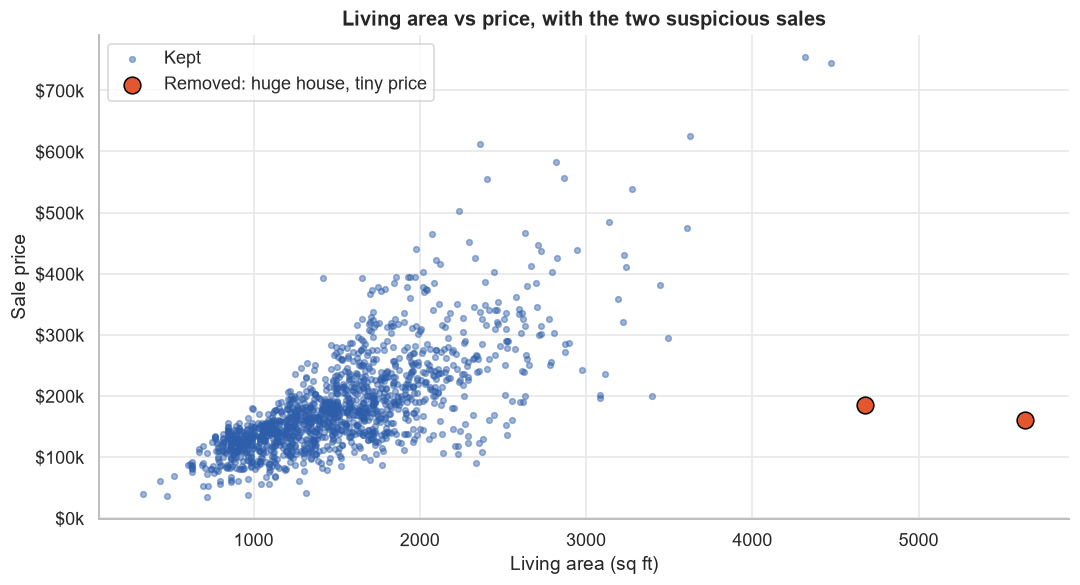

Removed 2 rows. 1,457 houses remain.


In [6]:
odd = (housing['GrLivArea'] > 4000) & (housing['SalePrice'] < 300_000)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(housing.loc[~odd, 'GrLivArea'], housing.loc[~odd, 'SalePrice'],
           s=14, alpha=0.45, color=PALETTE[0], label='Kept')
ax.scatter(housing.loc[odd, 'GrLivArea'], housing.loc[odd, 'SalePrice'],
           s=120, color=PALETTE[1], edgecolor='black', label='Removed: huge house, tiny price')
ax.yaxis.set_major_formatter(usd)
ax.set_title('Living area vs price, with the two suspicious sales')
ax.set_xlabel('Living area (sq ft)'); ax.set_ylabel('Sale price')
ax.legend()
plt.tight_layout(); plt.show()

housing = housing.loc[~odd].reset_index(drop=True)
print(f'Removed {odd.sum()} rows. {len(housing):,} houses remain.')

---
## 3. Exploratory Data Analysis

Before modelling we get to know the data: how prices are spread, which features move with the price,
and how location and building type change it. Good EDA tells us which models and which features are
likely to work.

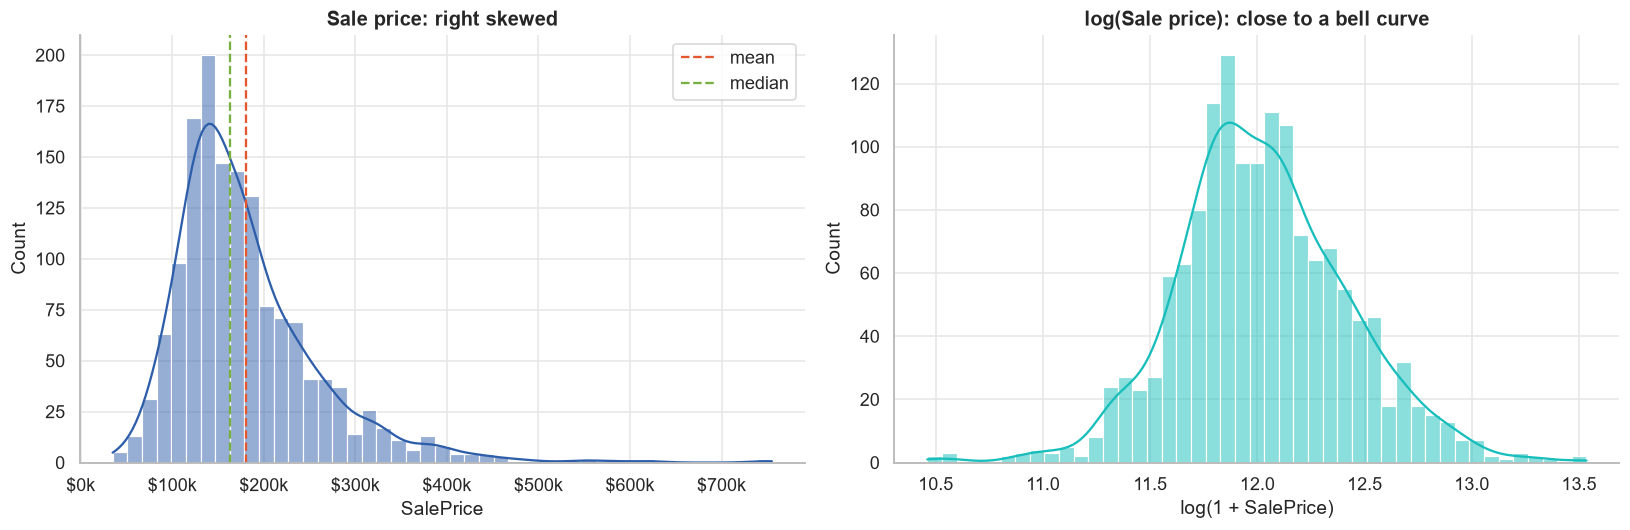

Mean $180,968, median $163,000, skew 1.88 -> 0.12 after the log.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(housing['SalePrice'], bins=45, kde=True, color=PALETTE[0], ax=axes[0])
axes[0].axvline(housing['SalePrice'].mean(), color=PALETTE[1], ls='--', label='mean')
axes[0].axvline(housing['SalePrice'].median(), color=PALETTE[4], ls='--', label='median')
axes[0].xaxis.set_major_formatter(usd)
axes[0].set_title('Sale price: right skewed')
axes[0].legend()

sns.histplot(np.log1p(housing['SalePrice']), bins=45, kde=True, color=PALETTE[2], ax=axes[1])
axes[1].set_title('log(Sale price): close to a bell curve')
axes[1].set_xlabel('log(1 + SalePrice)')

plt.tight_layout(); plt.show()
skew = housing['SalePrice'].skew()
print(f'Mean ${housing.SalePrice.mean():,.0f}, median ${housing.SalePrice.median():,.0f}, skew {skew:.2f}'
      f' -> {np.log1p(housing.SalePrice).skew():.2f} after the log.')

**What we see:** most houses sell between \$100k and \$250k, with a long tail of expensive ones.
A model that minimises squared error would chase that tail. Predicting **log(price)** instead makes
the errors *relative* (being \$20k off on a \$100k house counts more than on a \$500k house), which
is how buyers think about price. Every model below learns log(price) and we convert back to dollars.

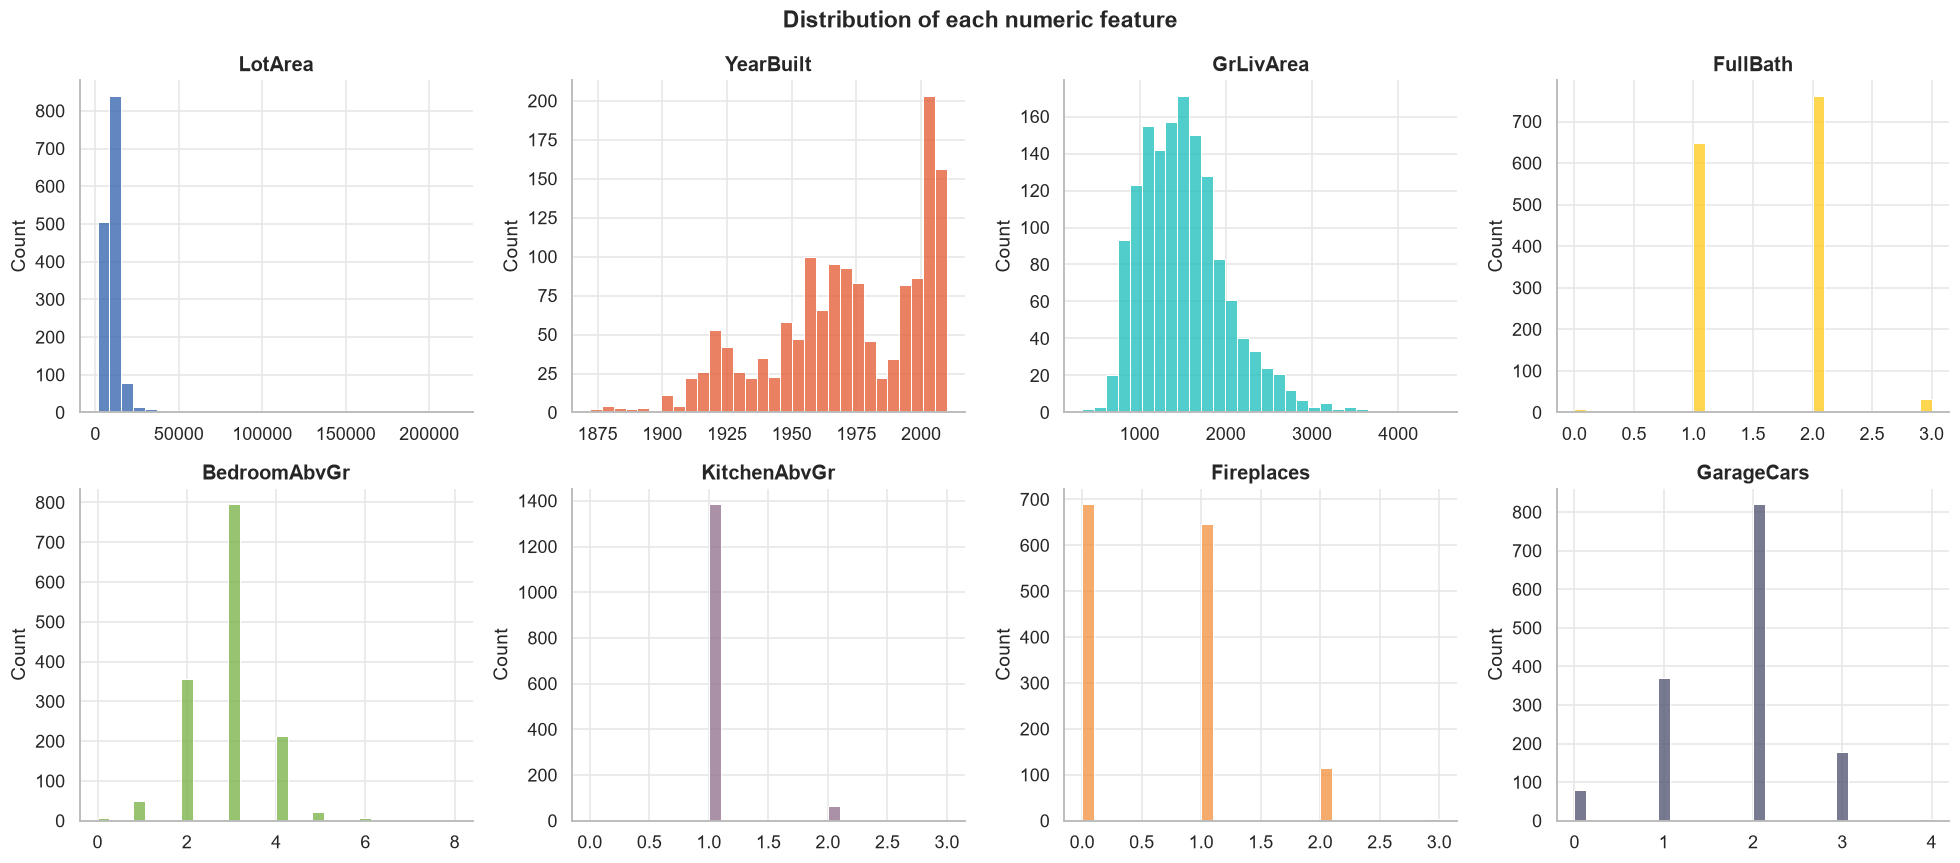

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col, color in zip(axes.flat, numeric, PALETTE):
    sns.histplot(housing[col].dropna(), bins=30, color=color, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
fig.suptitle('Distribution of each numeric feature', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

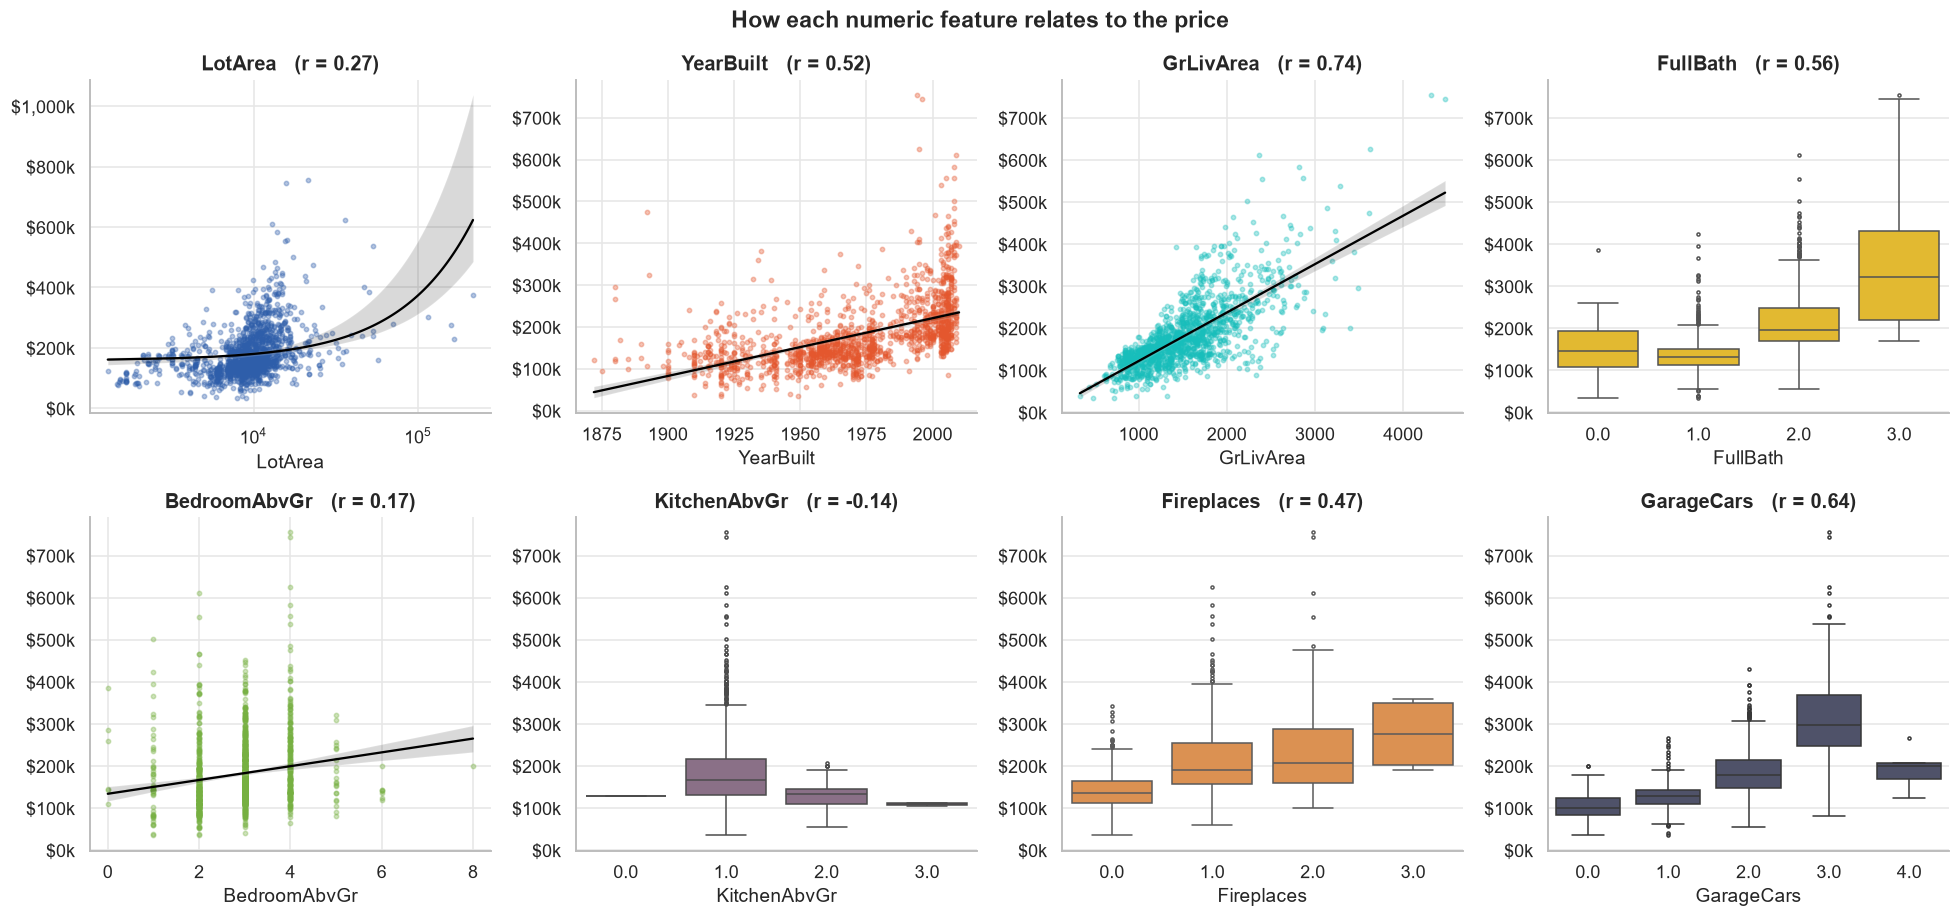

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, col, color in zip(axes.flat, numeric, PALETTE):
    sub = housing[[col, 'SalePrice']].dropna()
    if sub[col].nunique() <= 6:
        sns.boxplot(data=sub, x=col, y='SalePrice', color=color, ax=ax, fliersize=2)
    else:
        sns.regplot(data=sub, x=col, y='SalePrice', ax=ax, color=color,
                    scatter_kws={'s': 8, 'alpha': 0.35}, line_kws={'color': 'black', 'lw': 1.5})
    if col == 'LotArea':
        ax.set_xscale('log')
    r = sub[col].corr(sub['SalePrice'])
    ax.set_title(f'{col}   (r = {r:.2f})')
    ax.yaxis.set_major_formatter(usd); ax.set_ylabel('')
fig.suptitle('How each numeric feature relates to the price', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

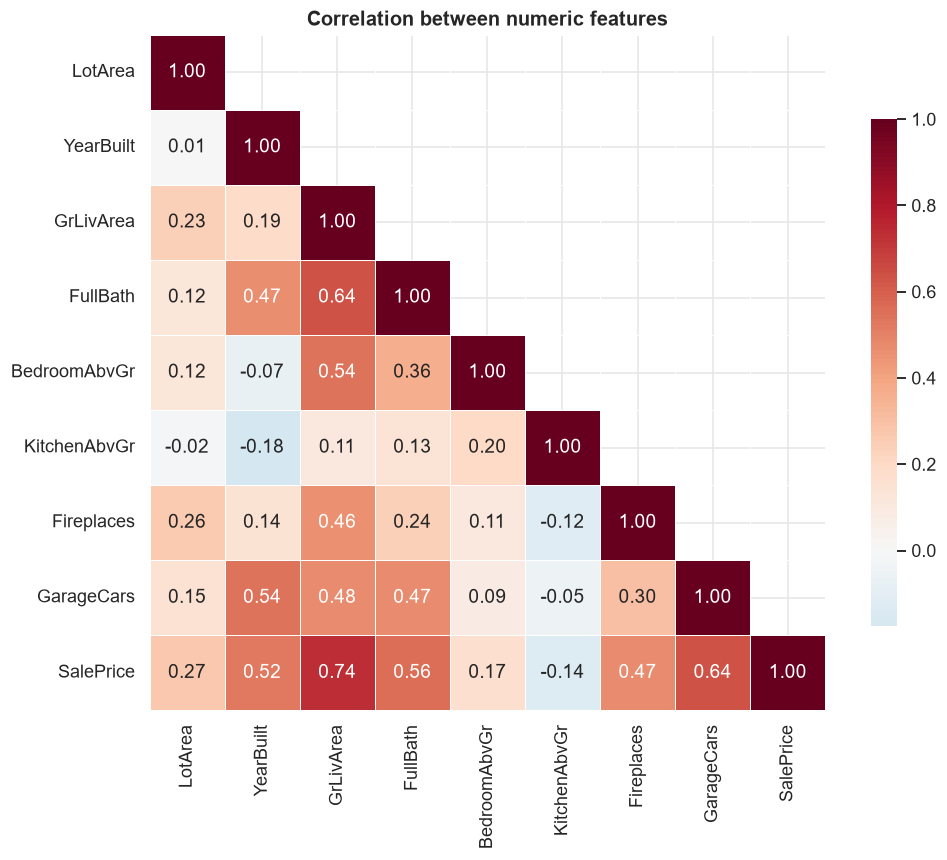

Strongest links with price: GrLivArea 0.74, GarageCars 0.64, FullBath 0.56


In [10]:
corr = housing[numeric + ['SalePrice']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=0.6, square=True, cbar_kws={'shrink': 0.75}, ax=ax)
ax.set_title('Correlation between numeric features')
plt.tight_layout(); plt.show()

top = corr['SalePrice'].drop('SalePrice').sort_values(ascending=False)
print('Strongest links with price:', ', '.join(f'{k} {v:.2f}' for k, v in top.head(3).items()))

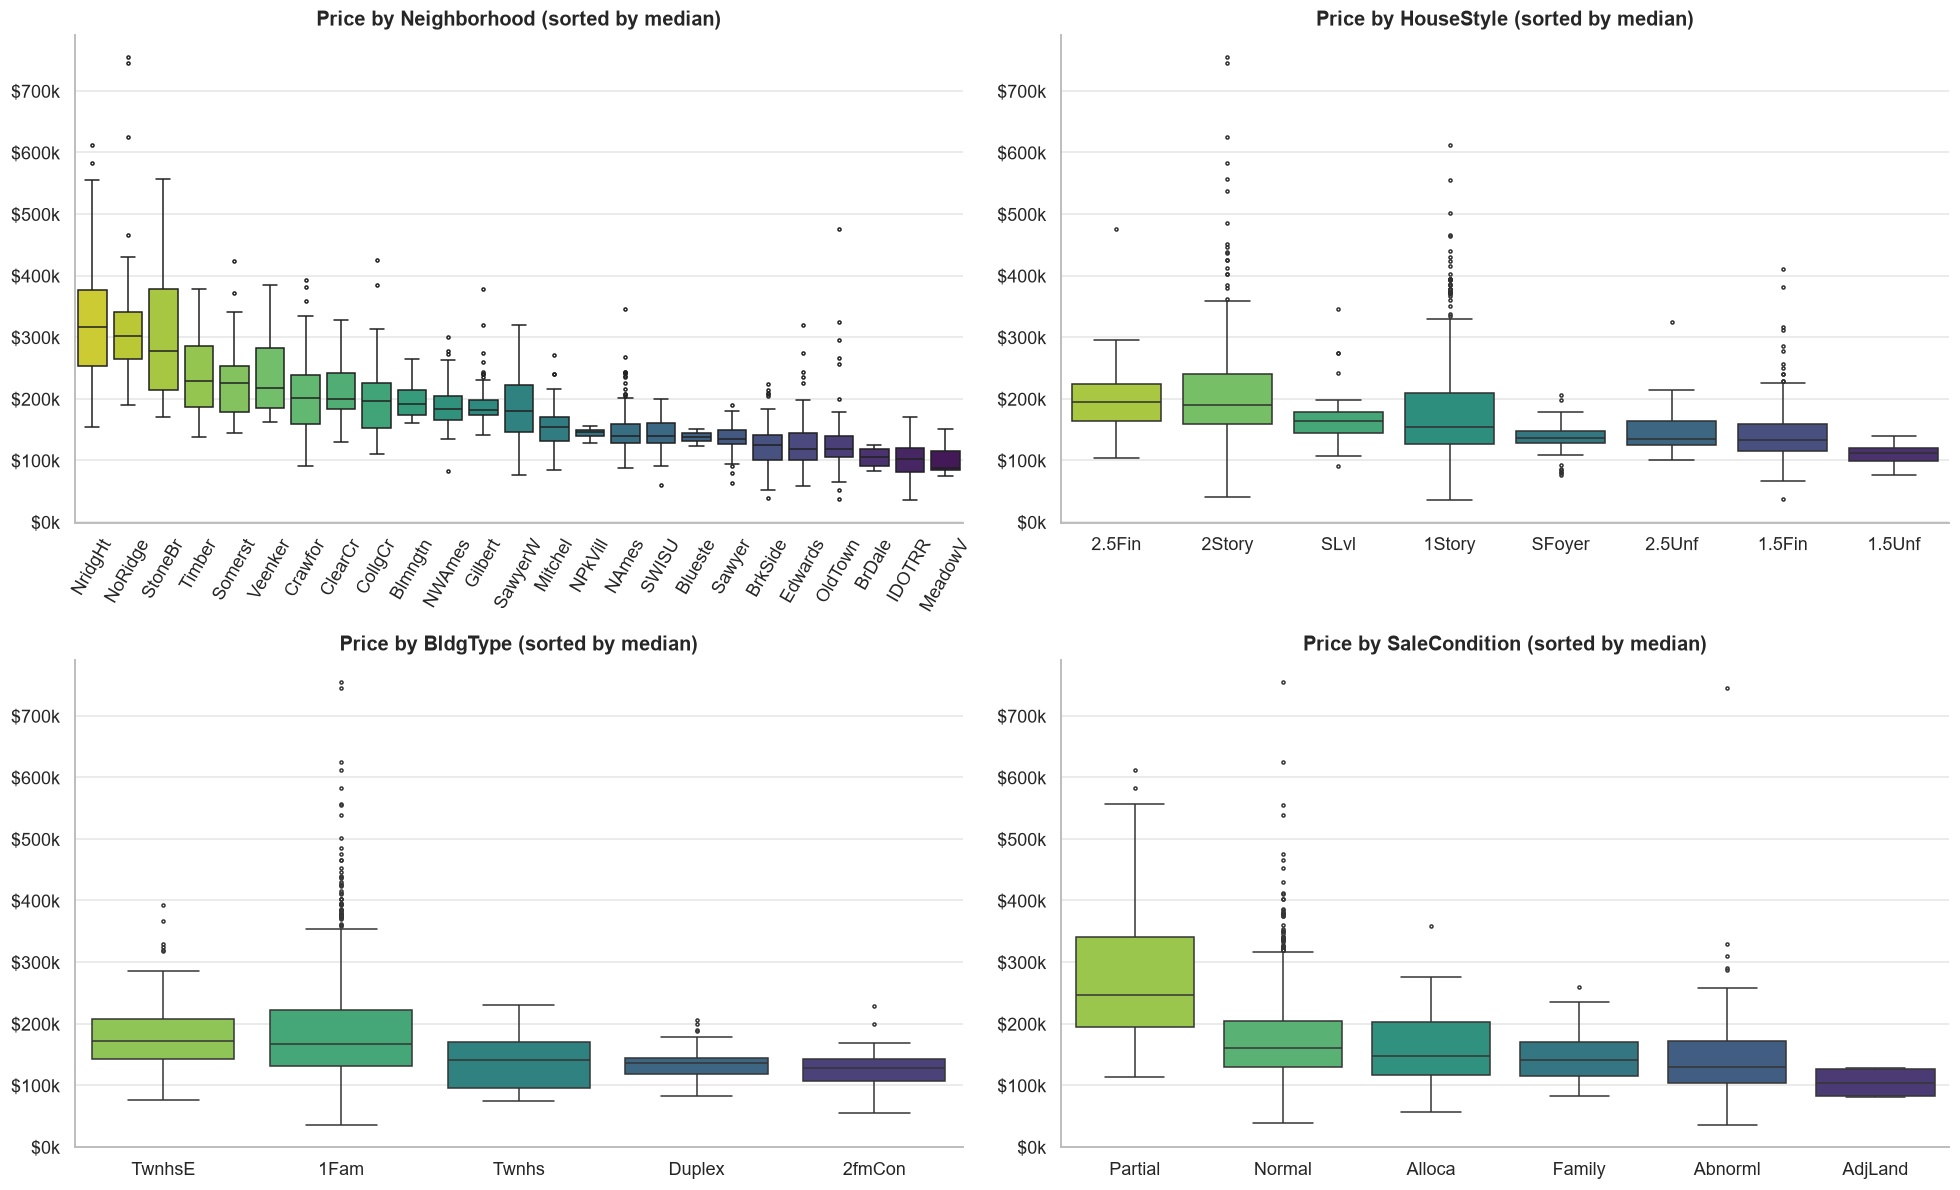

The most expensive area (NridgHt) has a median price 3.6x the cheapest (MeadowV).


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, col in zip(axes.flat, ['Neighborhood', 'HouseStyle', 'BldgType', 'SaleCondition']):
    order = housing.groupby(col)['SalePrice'].median().sort_values(ascending=False).index
    sns.boxplot(data=housing, x=col, y='SalePrice', order=order, ax=ax,
                palette=sns.color_palette('viridis_r', len(order)), fliersize=2)
    ax.set_title(f'Price by {col} (sorted by median)')
    ax.tick_params(axis='x', rotation=60 if col == 'Neighborhood' else 0)
    ax.yaxis.set_major_formatter(usd); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

nb = housing.groupby('Neighborhood')['SalePrice'].median()
print(f'The most expensive area ({nb.idxmax()}) has a median price {nb.max()/nb.min():.1f}x '
      f'the cheapest ({nb.idxmin()}).')

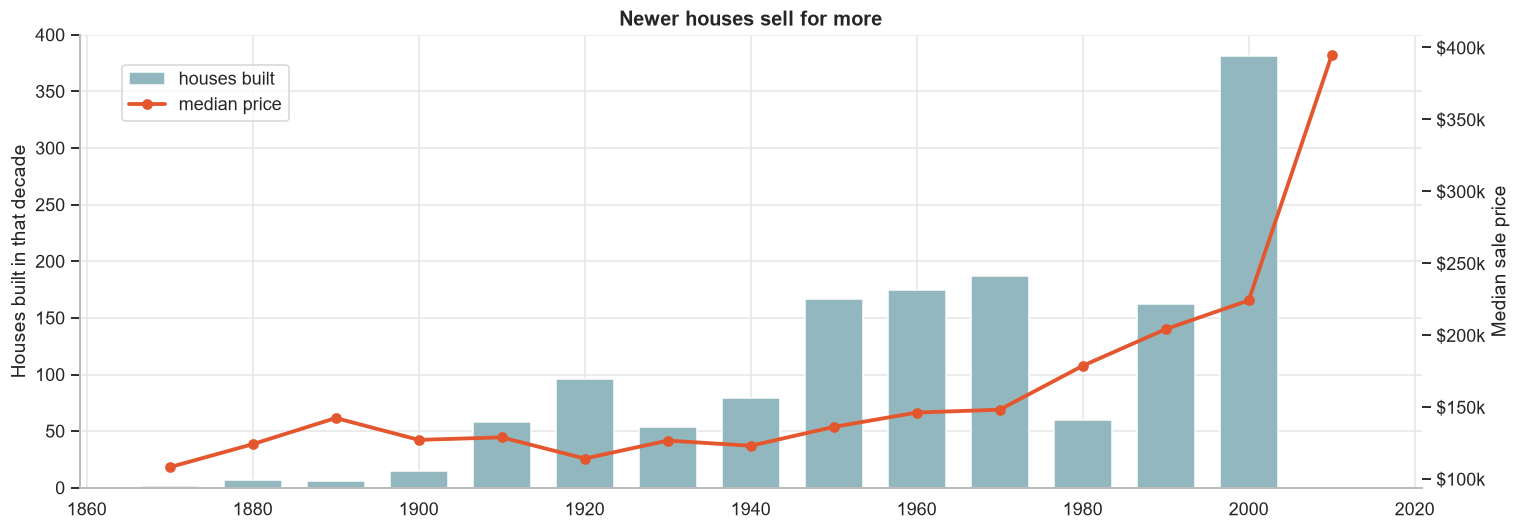

In [12]:
by_year = housing.dropna(subset=['YearBuilt']).copy()
by_year['Decade'] = (by_year['YearBuilt'] // 10 * 10).astype(int)
summary = by_year.groupby('Decade')['SalePrice'].agg(['median', 'count'])

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(summary.index, summary['count'], width=7, color=PALETTE[10], label='houses built')
ax1.set_ylabel('Houses built in that decade')
ax2 = ax1.twinx()
ax2.plot(summary.index, summary['median'], color=PALETTE[1], marker='o', lw=2.5, label='median price')
ax2.yaxis.set_major_formatter(usd); ax2.set_ylabel('Median sale price'); ax2.grid(False)
ax1.set_title('Newer houses sell for more')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88))
plt.tight_layout(); plt.show()

**What we learned from EDA**

* **Size is king.** `GrLivArea` and `GarageCars` have the strongest links with price.
* **Newer means pricier**, especially for houses built after 1990.
* **Location matters a lot.** The best neighbourhood costs several times the cheapest one, so the
  model needs `Neighborhood`.
* Some features barely move the price (`KitchenAbvGr`, `Street`, `Utilities`), so they will have
  little weight.
* Several relationships curve or flatten at the top. Predicting log(price) straightens many of them,
  so both straight-line and tree models are worth trying, which Section 5 does.

---
## 4. Feature Engineering and Selection

Feature engineering means creating new columns that make the pattern easier for a model to see.
A person valuing a house does this naturally: they think in terms of *age*, *rooms*, *space per room*.

| New feature | How it is made | Why it might help |
|---|---|---|
| `HouseAge` | 2010 minus `YearBuilt` | the data covers sales from 2006 to 2010 |
| `TotalRooms` | bedrooms + full baths + kitchens | one number for overall size |
| `AreaPerRoom` | `GrLivArea` / `TotalRooms` | spacious vs cramped |
| `HasGarage`, `HasFireplace` | 1 if present | simple yes/no extras |
| `LogLotArea` | log of `LotArea` | tames a few giant lots |

In [13]:
def add_features(df):
    df = df.copy()
    df['HouseAge'] = 2010 - df['YearBuilt']
    df['TotalRooms'] = df[['BedroomAbvGr', 'FullBath', 'KitchenAbvGr']].sum(axis=1, min_count=1)
    df['AreaPerRoom'] = df['GrLivArea'] / df['TotalRooms'].replace(0, np.nan)
    df['HasGarage'] = (df['GarageCars'] > 0).astype(float).where(df['GarageCars'].notna())
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(float).where(df['Fireplaces'].notna())
    df['LogLotArea'] = np.log1p(df['LotArea'])
    return df

data = add_features(housing)
X_all = data.drop(columns='SalePrice')
y_all = data['SalePrice']

num_features = X_all.select_dtypes('number').columns.tolist()
cat_features = X_all.select_dtypes(exclude='number').columns.tolist()
print(f'{len(num_features)} numeric features:', ', '.join(num_features))
print(f'{len(cat_features)} text features:', ', '.join(cat_features))

14 numeric features: LotArea, YearBuilt, GrLivArea, FullBath, BedroomAbvGr, KitchenAbvGr, Fireplaces, GarageCars, HouseAge, TotalRooms, AreaPerRoom, HasGarage, HasFireplace, LogLotArea
9 text features: Street, Utilities, Neighborhood, BldgType, HouseStyle, RoofStyle, Foundation, Electrical, SaleCondition


### Train / test split

We lock away **20% of the houses as a test set** and do not look at it until Section 7. All choices
(models, settings, features) are made using the other 80% with **5-fold cross-validation**. The split
is *stratified by price band*, so cheap and expensive houses appear in both parts in the same mix.

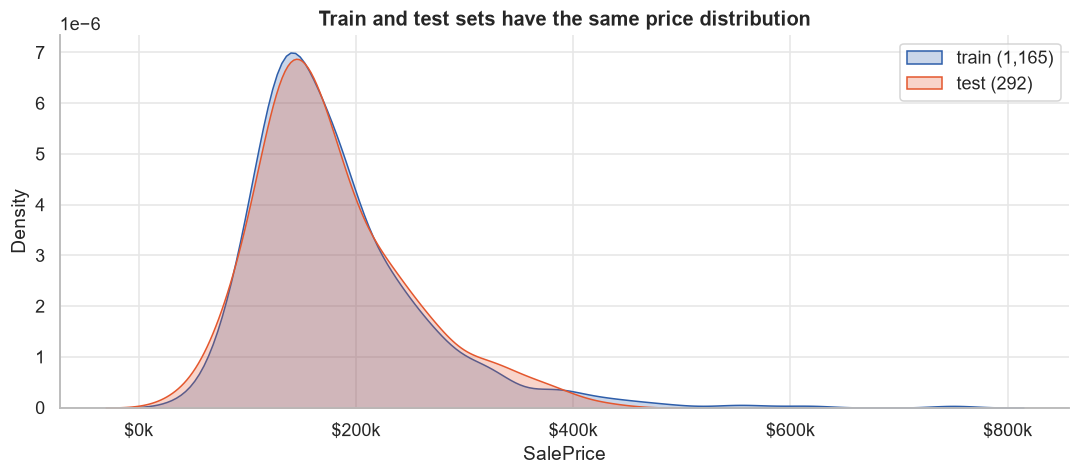

In [14]:
bands = pd.qcut(y_all, q=5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED, stratify=bands)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.kdeplot(y_train, fill=True, color=PALETTE[0], label=f'train ({len(y_train):,})', ax=ax)
sns.kdeplot(y_test, fill=True, color=PALETTE[1], label=f'test ({len(y_test):,})', ax=ax)
ax.xaxis.set_major_formatter(usd)
ax.set_title('Train and test sets have the same price distribution')
ax.legend()
plt.tight_layout(); plt.show()

CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

### Which features carry information?

Two independent views on the training set:

* **Correlation** finds straight-line links with log(price).
* **Mutual information** also finds curved and threshold links, and works for text columns.

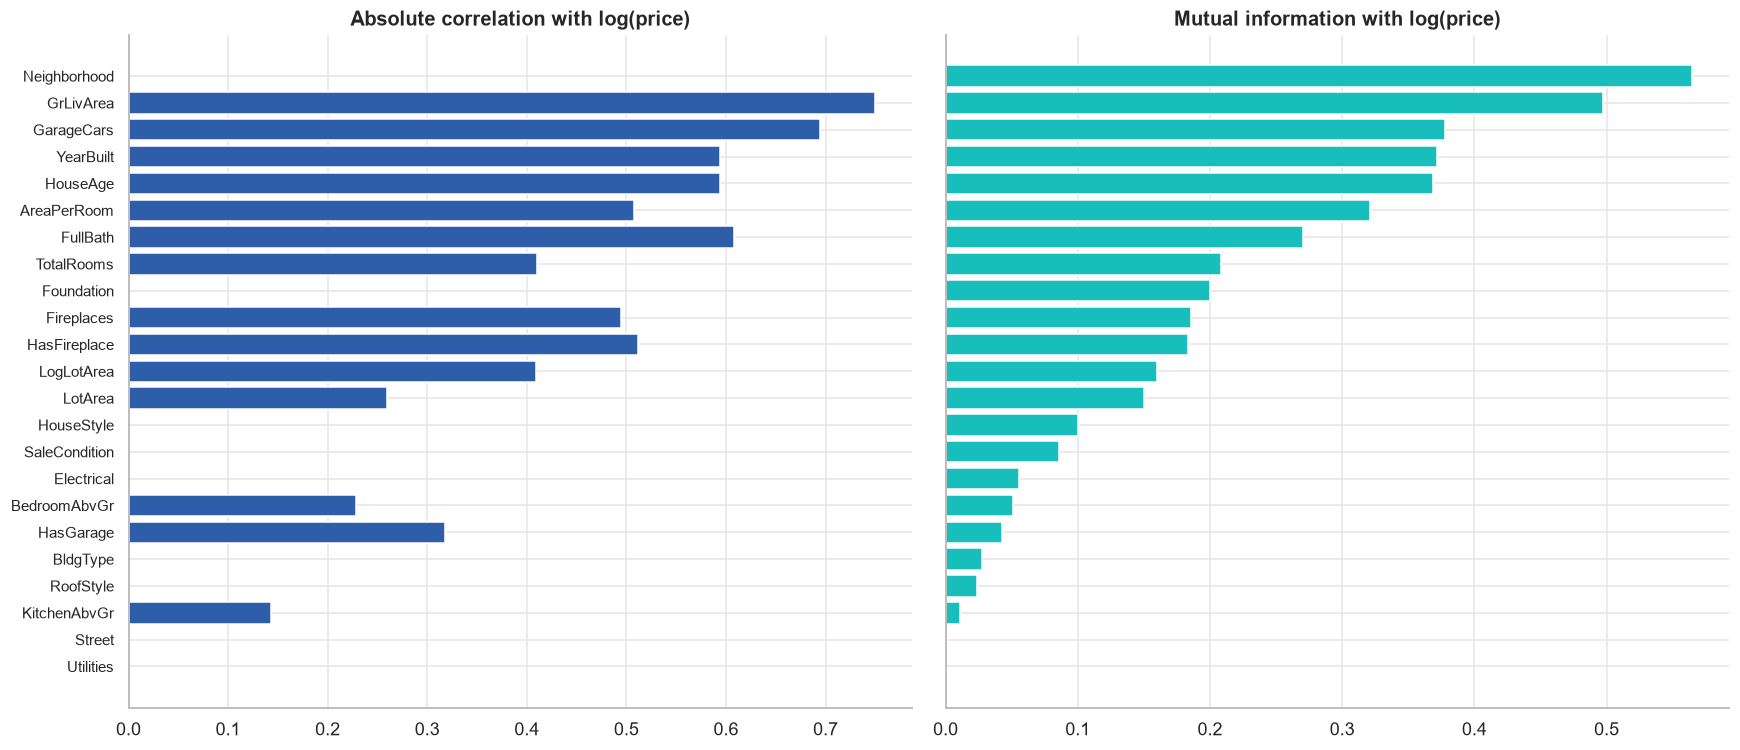

Almost no information: Utilities, Street


In [15]:
from sklearn.feature_selection import mutual_info_regression

Xi = X_train.copy()
for c in cat_features:
    Xi[c] = Xi[c].fillna('missing').astype('category').cat.codes
Xi = Xi.fillna(Xi.median(numeric_only=True))
mi = pd.Series(mutual_info_regression(Xi, np.log1p(y_train),
                                      discrete_features=[c in cat_features for c in Xi.columns],
                                      random_state=SEED), index=Xi.columns).sort_values()
corr_t = X_train[num_features].corrwith(np.log1p(y_train)).abs().reindex(mi.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
axes[0].barh(mi.index, corr_t.values, color=PALETTE[0])
axes[0].set_title('Absolute correlation with log(price)')
axes[1].barh(mi.index, mi.values, color=PALETTE[2])
axes[1].set_title('Mutual information with log(price)')
for ax in axes:
    ax.tick_params(axis='y', labelsize=10)
plt.tight_layout(); plt.show()

weak = mi[mi < 0.01].index.tolist()
print('Almost no information:', ', '.join(weak) if weak else 'none')

**Decision:** the strongest signals are size, age, garage and neighbourhood, and several engineered
features rank near the top. We drop only the columns that carry almost no information
(they are nearly constant). The models see everything else, because tree models and regularised linear
models pick their own features, and removing signal by hand usually costs accuracy.

In [16]:
drop_cols = [c for c in ['Street', 'Utilities'] if c in X_all.columns]
num_features = [c for c in num_features if c not in drop_cols]
cat_features = [c for c in cat_features if c not in drop_cols]
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
print(f'Using {len(num_features) + len(cat_features)} features. Dropped: {", ".join(drop_cols)}')

Using 21 features. Dropped: Street, Utilities


---
## 5. Model Building

Each model is a **pipeline**: fill missing values, encode text columns as 0/1 columns, scale numbers
when the model needs it, then learn **log(price)**. Because the whole pipeline is refit inside every
cross-validation fold, no information from the validation fold leaks into training.

| Family | Models | Idea |
|---|---|---|
| Baseline | Median | Always guess the median price. Any real model must beat it. |
| Linear | Linear Regression, Ridge, Lasso | Price as a weighted sum of features (Ridge and Lasso keep weights small) |
| Instance based | KNN | Price of the *k* most similar houses |
| Trees | Decision Tree, Random Forest | If/else rules; a forest averages many trees |
| Boosting | Gradient Boosting, XGBoost, LightGBM, CatBoost | Trees built one after another, each fixing the last one's mistakes |
| Kernel | SVM (SVR) | Fits a smooth curve in a transformed space |
| Neural network | MLP | Layers of neurons that learn their own features |

In [17]:
def make_preprocessor(scale=True, scaler=StandardScaler):
    num_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scale', scaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_features),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=5))]),
         cat_features),
    ], sparse_threshold=0)


def make_model(estimator, scale=True, scaler=StandardScaler):
    return TransformedTargetRegressor(
        regressor=Pipeline([('prep', make_preprocessor(scale, scaler)), ('model', estimator)]),
        func=np.log1p, inverse_func=np.expm1)


def gaussian_scaler():
    return QuantileTransformer(output_distribution='normal', n_quantiles=200, random_state=SEED)


models = {
    'Median (baseline)': make_model(DummyRegressor(strategy='median')),
    'Linear Regression': make_model(LinearRegression()),
    'Ridge':             make_model(Ridge(alpha=10)),
    'Lasso':             make_model(Lasso(alpha=0.0005, max_iter=20000)),
    'KNN':               make_model(KNeighborsRegressor(n_neighbors=8, weights='distance')),
    'Decision Tree':     make_model(DecisionTreeRegressor(random_state=SEED), scale=False),
    'Random Forest':     make_model(RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=-1), scale=False),
    'Gradient Boosting': make_model(GradientBoostingRegressor(random_state=SEED), scale=False),
    'XGBoost':           make_model(XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=4,
                                                 subsample=0.8, colsample_bytree=0.8,
                                                 random_state=SEED, n_jobs=-1), scale=False),
    'LightGBM':          make_model(LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15,
                                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                                  random_state=SEED, verbose=-1), scale=False),
    'CatBoost':          make_model(CatBoostRegressor(iterations=2000, learning_rate=0.03, depth=4, l2_leaf_reg=3,
                                                     random_seed=SEED, verbose=0, thread_count=1,
                                                     allow_writing_files=False), scale=False),
    'SVM (SVR)':         make_model(SVR(C=3, epsilon=0.02, gamma='scale'), scaler=RobustScaler),
    'Neural Network':    make_model(MLPRegressor(hidden_layer_sizes=(128, 64), alpha=3.0, solver='lbfgs',
                                                 max_iter=3000, random_state=SEED),
                                    scaler=gaussian_scaler),
}
print(f'{len(models)} models ready.')

13 models ready.


### Fair comparison with 5-fold cross-validation

Each model is trained 5 times, each time on 4/5 of the training houses and tested on the remaining 1/5.
We report the average and the spread. The spread matters: a model that is great on one fold and poor on
another is not reliable.

**Metrics**

| Metric | Meaning | Better |
|---|---|---|
| **MAE** | Average dollar error | lower |
| **RMSE** | Like MAE but punishes big misses more | lower |
| **MAPE** | Average error as a % of the price | lower |
| **R²** | Share of the price variation the model explains (1.0 = perfect) | higher |

In [18]:
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error',
           'MAPE': 'neg_mean_absolute_percentage_error', 'R2': 'r2'}

cv_rows, fold_r2 = [], {}
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=CV, scoring=scoring,
                       return_train_score=True, n_jobs=-1)
    fold_r2[name] = s['test_R2']
    cv_rows.append({'Model': name,
                    'MAE': -s['test_MAE'].mean(), 'RMSE': -s['test_RMSE'].mean(),
                    'MAPE %': -s['test_MAPE'].mean() * 100,
                    'R2': s['test_R2'].mean(), 'R2 std': s['test_R2'].std(),
                    'Train R2': s['train_R2'].mean(),
                    'Fit seconds': s['fit_time'].mean()})

cv_results = pd.DataFrame(cv_rows).set_index('Model').sort_values('R2', ascending=False)
(cv_results.style
     .format({'MAE': '${:,.0f}', 'RMSE': '${:,.0f}', 'MAPE %': '{:.2f}', 'R2': '{:.4f}',
              'R2 std': '{:.4f}', 'Train R2': '{:.4f}', 'Fit seconds': '{:.2f}'})
     .background_gradient(subset=['R2'], cmap='Greens')
     .background_gradient(subset=['MAE', 'MAPE %'], cmap='Reds'))

,MAE,RMSE,MAPE %,R2,R2 std,Train R2,Fit seconds
Model,,,,,,,
Neural Network,"$18,417","$27,301",10.75,0.8865,0.0109,0.9333,65.95
Lasso,"$19,027","$27,538",11.00,0.8843,0.0150,0.8982,0.07
CatBoost,"$18,448","$27,673",10.68,0.8831,0.0146,0.9723,7.41
XGBoost,"$18,595","$27,726",10.72,0.8818,0.0177,0.9862,2.15
Ridge,"$19,150","$28,004",11.07,0.8800,0.0164,0.8964,0.07
Gradient Boosting,"$19,509","$29,295",11.13,0.8683,0.0193,0.9422,0.59
LightGBM,"$19,497","$29,545",11.12,0.8672,0.0080,0.9671,1.37
Linear Regression,"$19,611","$29,566",11.36,0.8632,0.0360,0.9008,0.11
Random Forest,"$20,039","$30,831",11.38,0.8537,0.0231,0.9786,3.70


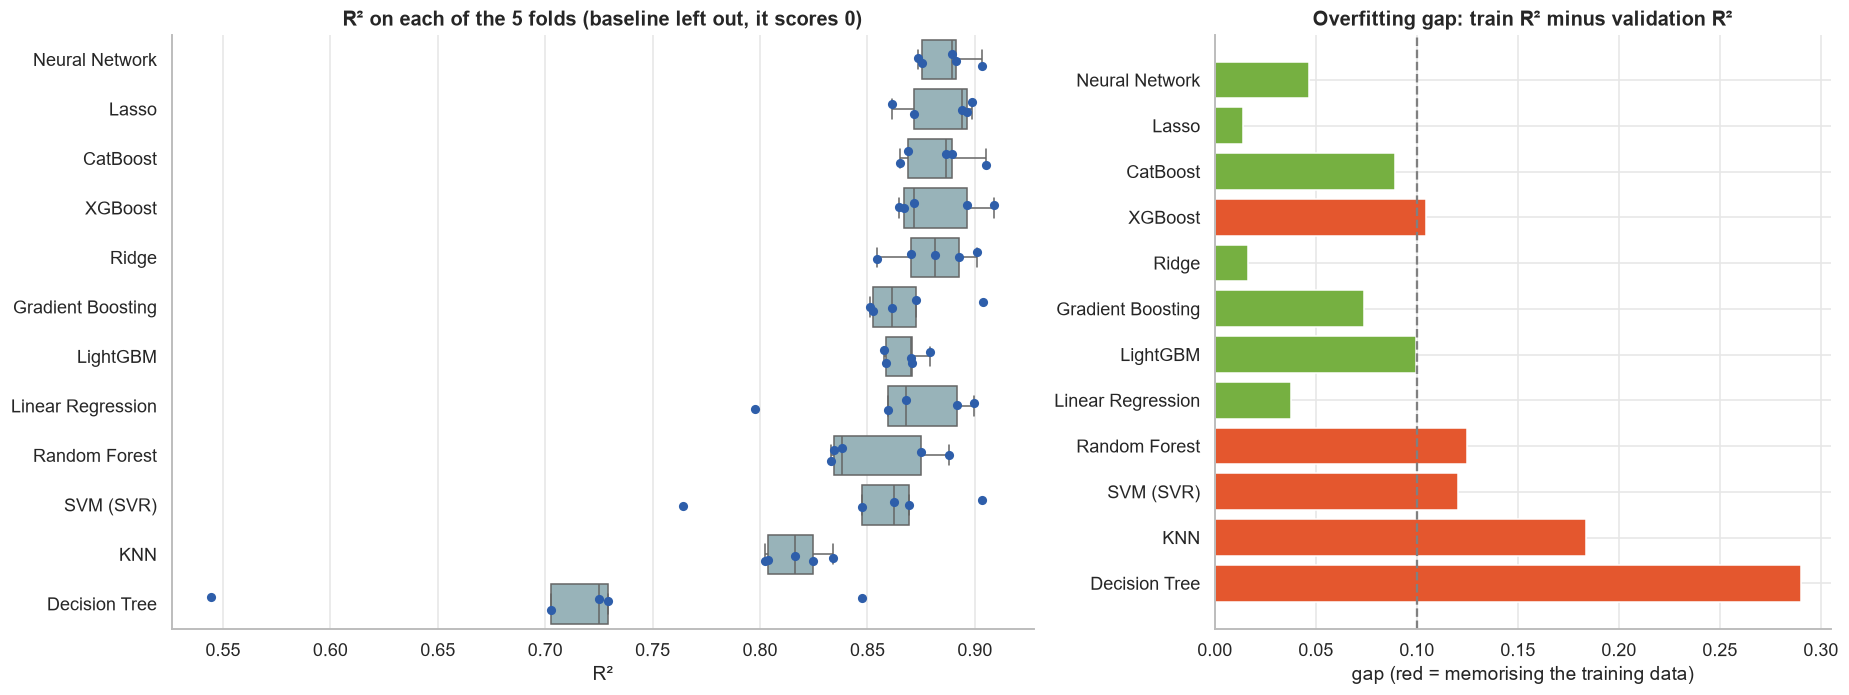

In [19]:
order = cv_results.index
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.4, 1]})

fold_df = pd.DataFrame(fold_r2)[order].melt(var_name='Model', value_name='R²')
fold_df = fold_df[fold_df['Model'] != 'Median (baseline)']
sns.boxplot(data=fold_df, y='Model', x='R²', ax=axes[0], color=PALETTE[10], fliersize=0)
sns.stripplot(data=fold_df, y='Model', x='R²', ax=axes[0], color=PALETTE[0], size=6, jitter=0.15)
axes[0].set_title('R² on each of the 5 folds (baseline left out, it scores 0)')
axes[0].set_ylabel('')

gap = (cv_results['Train R2'] - cv_results['R2']).drop('Median (baseline)')
colors = [PALETTE[1] if g > 0.1 else PALETTE[4] for g in gap]
axes[1].barh(gap.index, gap.values, color=colors)
axes[1].axvline(0.1, color='grey', ls='--')
axes[1].invert_yaxis()
axes[1].set_title('Overfitting gap: train R² minus validation R²')
axes[1].set_xlabel('gap (red = memorising the training data)')
plt.tight_layout(); plt.show()

**What we see**

* Every real model beats the baseline by a wide margin: the median guess is off by about \$56k, the
  good models by about \$18k to \$20k.
* The **Neural Network** comes first. It only works this well because of `gaussian_scaler`: with plain
  scaling, a handful of giant lots pushed its inputs to extreme values and its error exploded.
* **Lasso**, a plain linear model, is a close second. Predicting log(price) makes most relationships
  nearly straight lines, so a well regularised linear model is hard to beat on this data.
* The single **Decision Tree** scores a perfect 1.0 on training data but only about 0.71 on validation
  folds: it *memorises* houses instead of learning rules. Averaging many trees (**Random Forest**) or
  building them carefully one after another (**boosting**) closes most of that gap.

---
## 6. Model Optimization

Every model has **hyperparameters**: settings we choose before training, like how deep a tree may grow
or how fast boosting learns. We tune the strongest models with **randomized search**: try many random
combinations, score each with 5-fold cross-validation, keep the best.

Then we build a **stacked ensemble**: several tuned models make predictions, and a simple linear model
learns how much to trust each one. Different models make different mistakes, so combining them often
beats the best single model.

The stack uses five models of different kinds: two boosting models, a kernel model, a linear model and a
neural network. We also tried adding CatBoost; it is strong on its own, but it did not lower the stack's
cross-validated error (it makes the same kind of mistakes as the other boosting models) and it tripled the
run time, so it was left out. More models are only worth it when they bring something new.

In [20]:
search_spaces = {
    'LightGBM': {
        'regressor__model__n_estimators': [400, 700, 1000, 1500],
        'regressor__model__learning_rate': [0.01, 0.02, 0.03, 0.05],
        'regressor__model__num_leaves': [7, 15, 31],
        'regressor__model__min_child_samples': [5, 10, 20, 30],
        'regressor__model__colsample_bytree': [0.5, 0.7, 0.9],
        'regressor__model__reg_lambda': [0, 1, 5, 10],
    },
    'XGBoost': {
        'regressor__model__n_estimators': [400, 700, 1000, 1500],
        'regressor__model__learning_rate': [0.01, 0.02, 0.03, 0.05],
        'regressor__model__max_depth': [2, 3, 4, 5],
        'regressor__model__min_child_weight': [1, 3, 5],
        'regressor__model__colsample_bytree': [0.5, 0.7, 0.9],
        'regressor__model__reg_lambda': [0.5, 1, 5, 10],
    },
    'SVM (SVR)': {
        'regressor__model__C': [0.3, 1, 3, 10, 30],
        'regressor__model__epsilon': [0.005, 0.01, 0.02, 0.05],
        'regressor__model__gamma': ['scale', 0.003, 0.01, 0.03],
    },
    'Lasso': {'regressor__model__alpha': np.logspace(-4.5, -2, 40)},
    'Neural Network': {
        'regressor__model__hidden_layer_sizes': [(64,), (128,), (64, 32), (128, 64)],
        'regressor__model__alpha': [1, 3, 10, 30],
    },
}

tuned, tuning_rows = {}, []
for name, space in search_spaces.items():
    search = RandomizedSearchCV(models[name], space, n_iter=min(40, np.prod([len(v) for v in space.values()])),
                                cv=CV, scoring='neg_mean_absolute_error', random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    best = {k.split('__')[-1]: v for k, v in search.best_params_.items()}
    tuning_rows.append({'Model': name, 'MAE before': cv_results.loc[name, 'MAE'],
                        'MAE after': -search.best_score_, 'Best settings': best})

tuning = pd.DataFrame(tuning_rows).set_index('Model')
tuning['Improvement'] = 1 - tuning['MAE after'] / tuning['MAE before']
tuning.style.format({'MAE before': '${:,.0f}', 'MAE after': '${:,.0f}', 'Improvement': '{:.1%}'})

,MAE before,MAE after,Best settings,Improvement
Model,,,,
LightGBM,"$19,497","$18,438","{'reg_lambda': 0, 'num_leaves': 15, 'n_estimators': 700, 'min_child_samples': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.5}",5.4%
XGBoost,"$18,595","$18,456","{'reg_lambda': 0.5, 'n_estimators': 700, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.5}",0.8%
SVM (SVR),"$19,981","$18,015","{'gamma': 0.003, 'epsilon': 0.05, 'C': 10}",9.8%
Lasso,"$19,027","$19,008",{'alpha': np.float64(0.00038881551803080855)},0.1%
Neural Network,"$18,417","$18,417","{'hidden_layer_sizes': (128, 64), 'alpha': 3}",0.0%


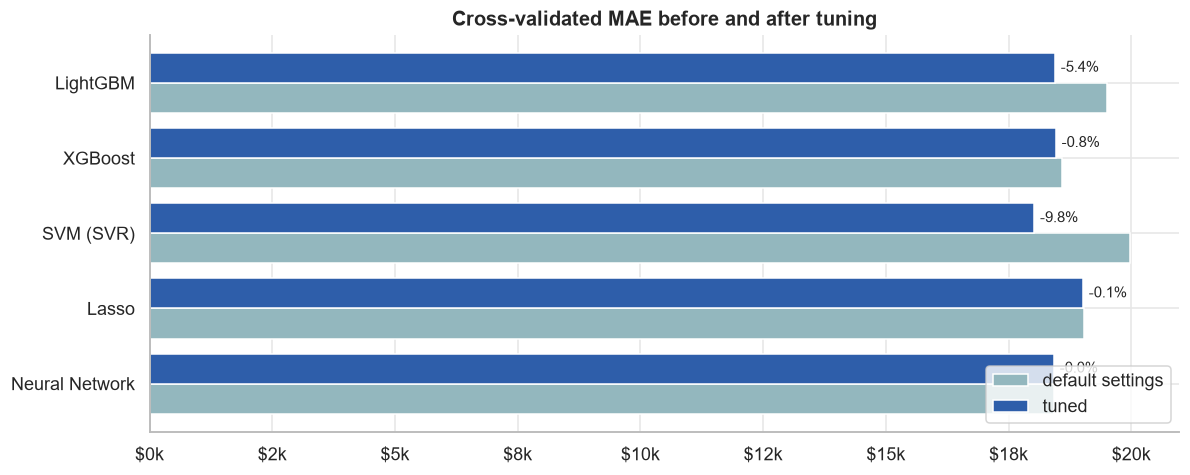

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.5))
idx = np.arange(len(tuning))
ax.barh(idx + 0.2, tuning['MAE before'], height=0.4, color=PALETTE[10], label='default settings')
bars = ax.barh(idx - 0.2, tuning['MAE after'], height=0.4, color=PALETTE[0], label='tuned')
ax.bar_label(bars, labels=[f'-{v:.1%}' for v in tuning['Improvement']], padding=4, fontsize=10)
ax.set_yticks(idx, tuning.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(usd)
ax.set_title('Cross-validated MAE before and after tuning')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [22]:
stack = StackingRegressor(
    estimators=[('lgbm', tuned['LightGBM']), ('xgb', tuned['XGBoost']), ('svr', tuned['SVM (SVR)']),
                ('lasso', tuned['Lasso']), ('mlp', tuned['Neural Network'])],
    final_estimator=Ridge(alpha=1.0, positive=True), cv=CV, n_jobs=-1)

s = cross_validate(stack, X_train, y_train, cv=CV, scoring=scoring, n_jobs=-1)
stack_row = {'MAE': -s['test_MAE'].mean(), 'RMSE': -s['test_RMSE'].mean(),
             'MAPE %': -s['test_MAPE'].mean() * 100, 'R2': s['test_R2'].mean()}
print('Stacked ensemble, 5-fold CV:')
print(f"  MAE ${stack_row['MAE']:,.0f}   MAPE {stack_row['MAPE %']:.2f}%   R2 {stack_row['R2']:.4f}")

stack.fit(X_train, y_train)
weights = pd.Series(stack.final_estimator_.coef_,
                    index=['LightGBM', 'XGBoost', 'SVR', 'Lasso', 'Neural Network'])
print('\nHow much the ensemble trusts each model:')
print((weights / weights.sum()).round(3).to_string())

Stacked ensemble, 5-fold CV:
  MAE $17,978   MAPE 10.50%   R2 0.8954



How much the ensemble trusts each model:
LightGBM          0.005
XGBoost           0.208
SVR               0.198
Lasso             0.291
Neural Network    0.299


---
## 7. Model Evaluation and Explainability

Now, for the first time, we use the **test set**: 20% of houses no model has ever seen. This is the
honest estimate of how the model would do on a new listing.

The **final model is chosen by its cross-validated error** from Sections 5 and 6, not by the test score.
Picking the winner on the test set would quietly tune to it and make the result look better than it is.

In [23]:
final_models = {'Linear Regression': models['Linear Regression'], 'Decision Tree': models['Decision Tree'],
                'Random Forest': models['Random Forest'], 'CatBoost': models['CatBoost'],
                **{f'{k} (tuned)': v for k, v in tuned.items()}, 'Stacked Ensemble': stack}
cv_mae = {**{n: cv_results.loc[n, 'MAE'] for n in ['Linear Regression', 'Decision Tree', 'Random Forest', 'CatBoost']},
          **{f'{k} (tuned)': tuning.loc[k, 'MAE after'] for k in tuned}, 'Stacked Ensemble': stack_row['MAE']}

test_rows, test_preds = [], {}
for name, model in final_models.items():
    if name != 'Stacked Ensemble' and '(tuned)' not in name:
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    test_preds[name] = pred
    test_rows.append({'Model': name, 'MAE': mean_absolute_error(y_test, pred),
                      'RMSE': mean_squared_error(y_test, pred) ** 0.5,
                      'MAPE %': mean_absolute_percentage_error(y_test, pred) * 100,
                      'R2': r2_score(y_test, pred)})

test_results = pd.DataFrame(test_rows).set_index('Model')
test_results.insert(0, 'CV MAE', pd.Series(cv_mae))
test_results = test_results.sort_values('CV MAE')
BEST = test_results.index[0]
print(f'Final model (lowest cross-validated MAE): {BEST}')
(test_results.style
     .format({'CV MAE': '${:,.0f}', 'MAE': '${:,.0f}', 'RMSE': '${:,.0f}', 'MAPE %': '{:.2f}', 'R2': '{:.4f}'})
     .highlight_min(subset=['MAE', 'RMSE', 'MAPE %'], color='#C6E9C3')
     .highlight_max(subset=['R2'], color='#C6E9C3'))

Final model (lowest cross-validated MAE): Stacked Ensemble


,CV MAE,MAE,RMSE,MAPE %,R2
Model,,,,,
Stacked Ensemble,"$17,978","$19,037","$27,162",12.52,0.8528
SVM (SVR) (tuned),"$18,015","$19,208","$27,642",12.82,0.8475
Neural Network (tuned),"$18,417","$19,780","$28,457",13.00,0.8384
LightGBM (tuned),"$18,438","$19,295","$27,745",12.67,0.8464
CatBoost,"$18,448","$18,847","$27,383",12.37,0.8504
XGBoost (tuned),"$18,456","$18,843","$27,723",12.40,0.8467
Lasso (tuned),"$19,008","$20,650","$29,050",13.18,0.8316
Linear Regression,"$19,611","$20,817","$28,977",13.34,0.8325
Random Forest,"$20,039","$20,139","$29,823",13.28,0.8226


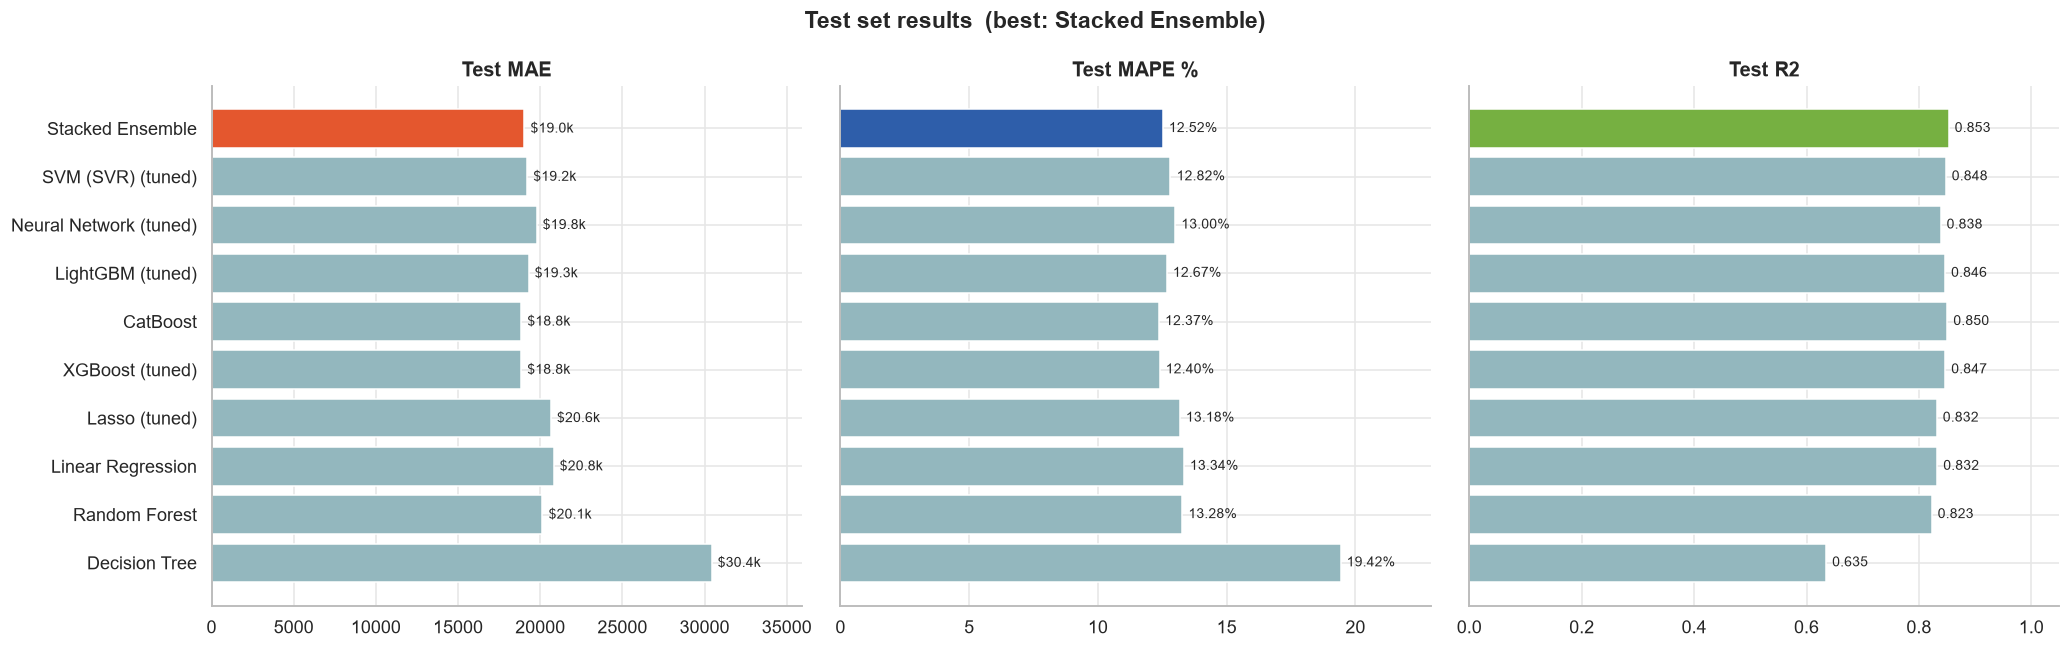

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)
names = test_results.index[::-1]
for ax, metric, color, fmt in [(axes[0], 'MAE', PALETTE[1], lambda v: f'${v/1000:,.1f}k'),
                               (axes[1], 'MAPE %', PALETTE[0], lambda v: f'{v:.2f}%'),
                               (axes[2], 'R2', PALETTE[4], lambda v: f'{v:.3f}')]:
    vals = test_results.loc[names, metric]
    bars = ax.barh(names, vals, color=[color if n == BEST else PALETTE[10] for n in names])
    ax.bar_label(bars, labels=[fmt(v) for v in vals], padding=4, fontsize=9)
    ax.set_title(f'Test {metric}')
    ax.set_xlim(0, vals.max() * 1.18 if metric != 'R2' else 1.05)
fig.suptitle(f'Test set results  (best: {BEST})', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

**What we see:** the stacked ensemble, chosen before looking at the test set, explains about 85% of the
variation in prices of houses it has never seen, and its typical miss is about \$19k. The test scores are a
little worse than the cross-validation scores, which is normal: the test set is small (292 houses), so a few
hard houses move the numbers. The top five models are within about \$1k of each other, which is within
that noise. The order would shuffle with a different split, the overall level would not.

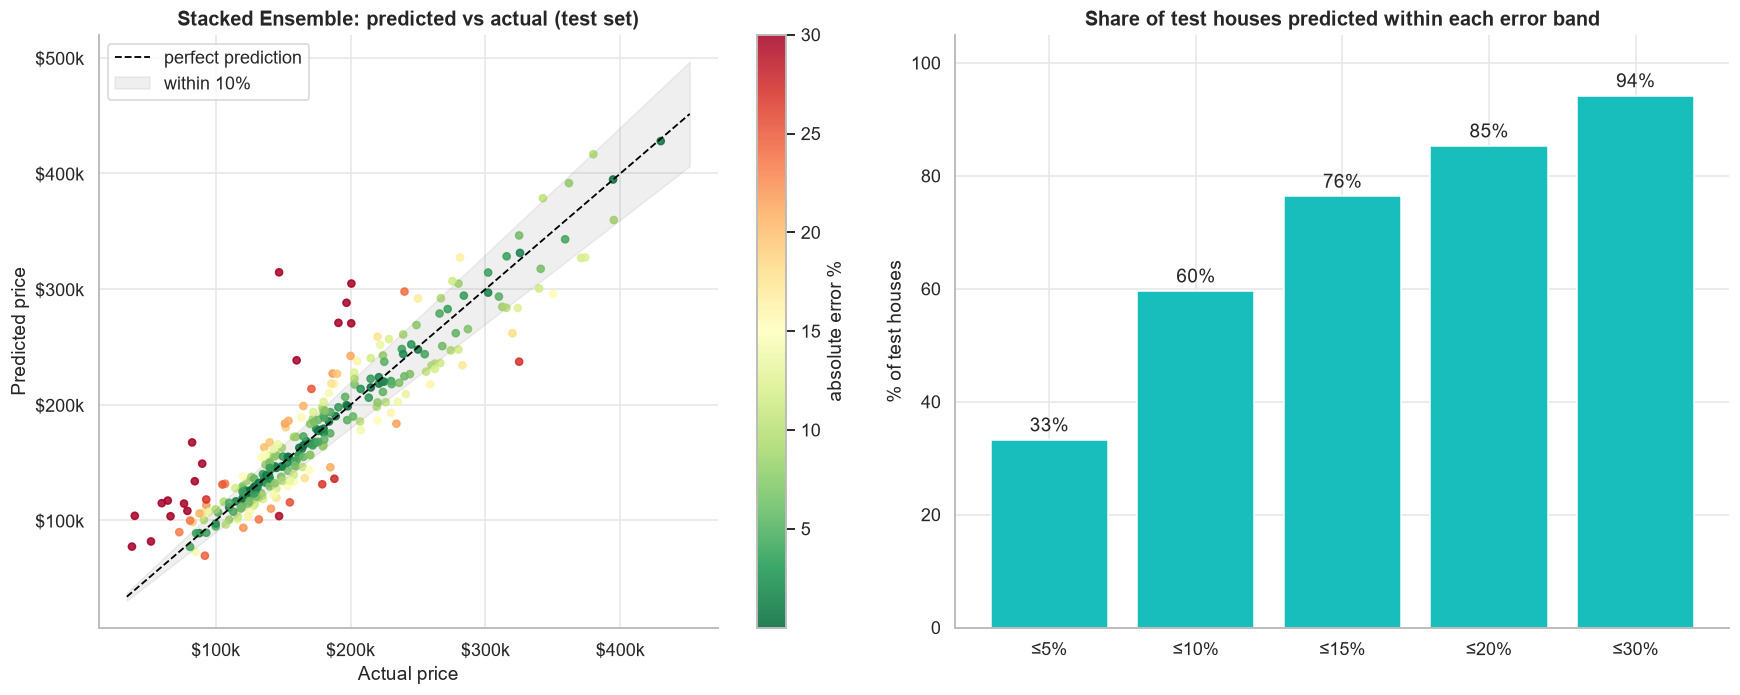

60% of unseen houses are priced within 10% of their real sale price.


In [25]:
best_pred = test_preds[BEST]
err_pct = (best_pred - y_test) / y_test * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sc = axes[0].scatter(y_test, best_pred, c=np.abs(err_pct), cmap='RdYlGn_r', vmax=30, s=22, alpha=0.85)
lims = [y_test.min() * 0.9, y_test.max() * 1.05]
axes[0].plot(lims, lims, 'k--', lw=1.2, label='perfect prediction')
axes[0].fill_between(lims, [v * 0.9 for v in lims], [v * 1.1 for v in lims], color='grey', alpha=0.12,
                     label='within 10%')
axes[0].xaxis.set_major_formatter(usd); axes[0].yaxis.set_major_formatter(usd)
axes[0].set_xlabel('Actual price'); axes[0].set_ylabel('Predicted price')
axes[0].set_title(f'{BEST}: predicted vs actual (test set)')
axes[0].legend(loc='upper left')
plt.colorbar(sc, ax=axes[0], label='absolute error %')

within = [(np.abs(err_pct) <= t).mean() * 100 for t in (5, 10, 15, 20, 30)]
bars = axes[1].bar(['≤5%', '≤10%', '≤15%', '≤20%', '≤30%'], within, color=PALETTE[2])
axes[1].bar_label(bars, labels=[f'{w:.0f}%' for w in within], padding=3)
axes[1].set_ylim(0, 105)
axes[1].set_title('Share of test houses predicted within each error band')
axes[1].set_ylabel('% of test houses')
plt.tight_layout(); plt.show()
print(f'{within[1]:.0f}% of unseen houses are priced within 10% of their real sale price.')

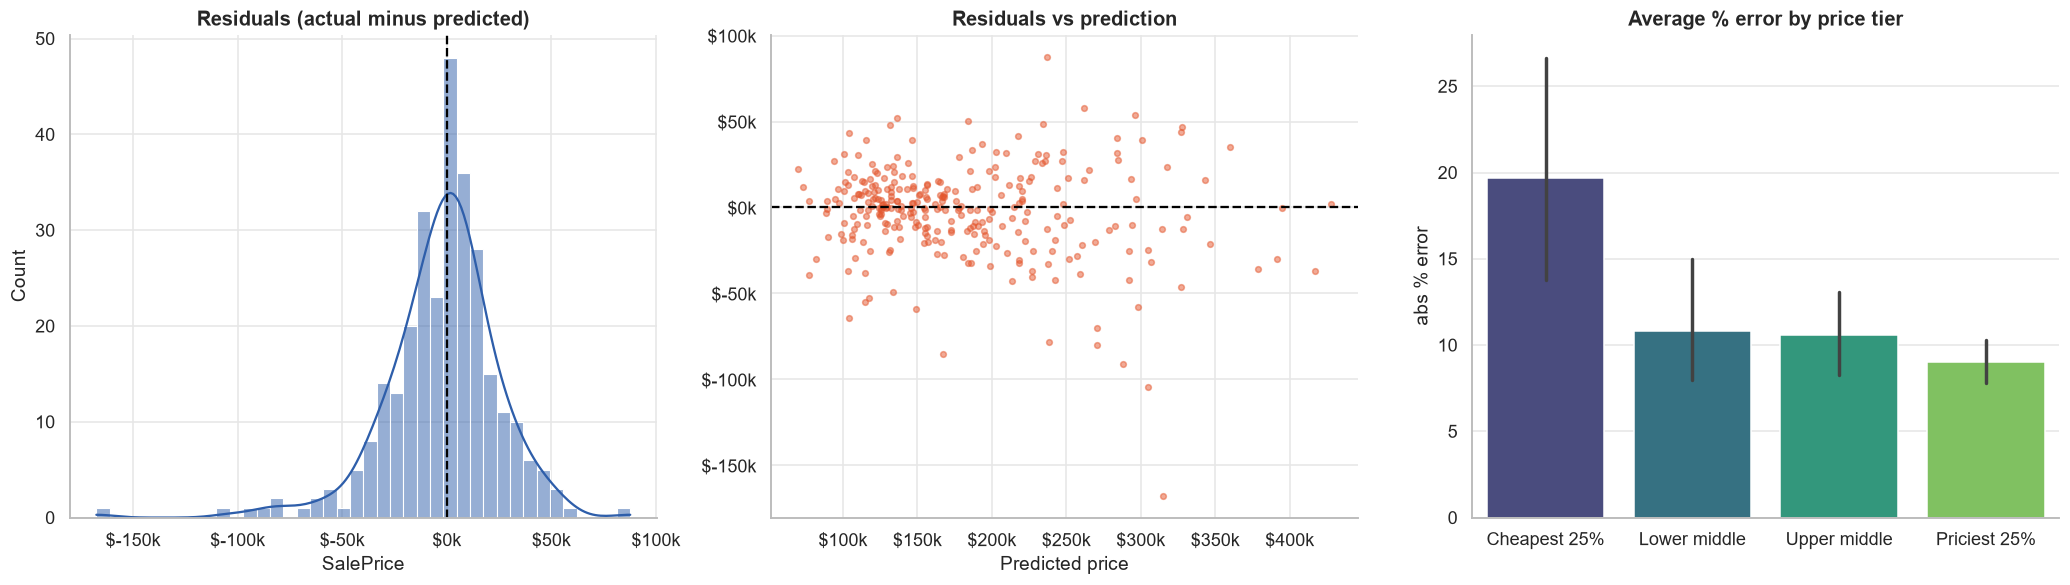

Mean residual $-2,291 (close to 0 means no systematic over or under pricing).


In [26]:
resid = y_test - best_pred
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

sns.histplot(resid, bins=40, kde=True, color=PALETTE[0], ax=axes[0])
axes[0].axvline(0, color='black', ls='--')
axes[0].xaxis.set_major_formatter(usd)
axes[0].set_title('Residuals (actual minus predicted)')

axes[1].scatter(best_pred, resid, s=14, alpha=0.5, color=PALETTE[1])
axes[1].axhline(0, color='black', ls='--')
axes[1].xaxis.set_major_formatter(usd); axes[1].yaxis.set_major_formatter(usd)
axes[1].set_title('Residuals vs prediction'); axes[1].set_xlabel('Predicted price')

tier = pd.qcut(y_test, 4, labels=['Cheapest 25%', 'Lower middle', 'Upper middle', 'Priciest 25%'])
tier_err = pd.DataFrame({'tier': tier, 'abs % error': np.abs(err_pct)})
sns.barplot(data=tier_err, x='tier', y='abs % error', ax=axes[2], palette='viridis', errorbar=('ci', 95))
axes[2].set_title('Average % error by price tier'); axes[2].set_xlabel('')
plt.tight_layout(); plt.show()
print(f'Mean residual ${resid.mean():,.0f} (close to 0 means no systematic over or under pricing).')

**What we see:** the errors are centred on zero and roughly bell shaped, so the model does not over or
under price houses in general. In percent terms the **cheapest quarter** is the hardest: a \$20k miss on a
\$70k house is almost 30%. Cheap houses are often old, small and sold under unusual conditions, and the
data has few of them. For mid and upper priced houses the model is typically within about 10%.

### Does the model need more data? Learning curve

We train the best single model on growing slices of the training data. If the validation error keeps
falling as data grows, more houses would help. If it has flattened, the model has learned what these
19 columns can teach.

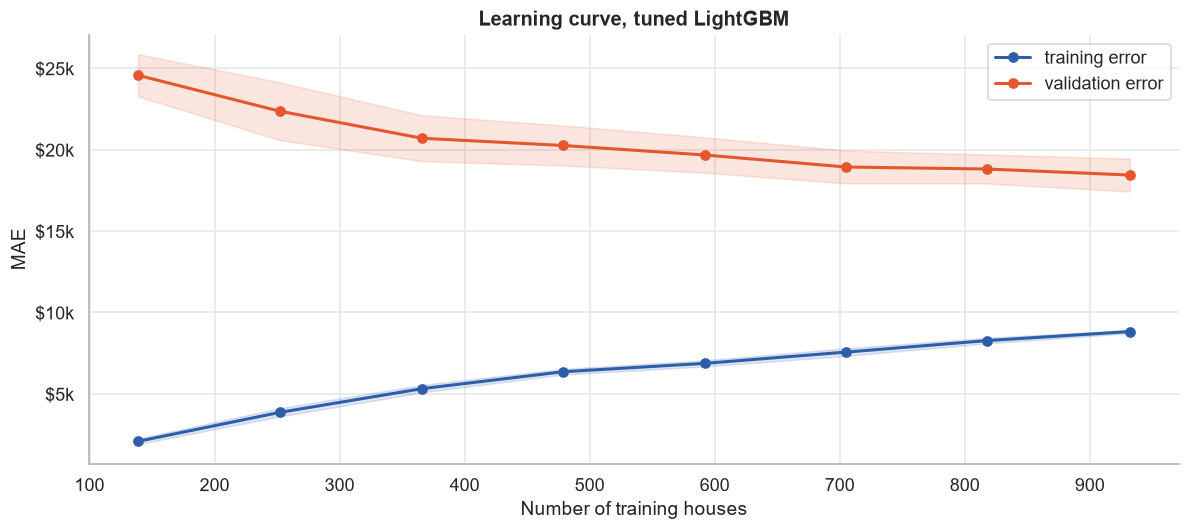

In [27]:
lc_model = tuned['LightGBM']
sizes, tr, va = learning_curve(lc_model, X_train, y_train, cv=CV, n_jobs=-1,
                               train_sizes=np.linspace(0.15, 1.0, 8),
                               scoring='neg_mean_absolute_error')
fig, ax = plt.subplots(figsize=(11, 5))
for scores, label, color in [(-tr, 'training error', PALETTE[0]), (-va, 'validation error', PALETTE[1])]:
    ax.plot(sizes, scores.mean(1), marker='o', color=color, lw=2, label=label)
    ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1),
                    color=color, alpha=0.15)
ax.yaxis.set_major_formatter(usd)
ax.set_xlabel('Number of training houses'); ax.set_ylabel('MAE')
ax.set_title('Learning curve, tuned LightGBM')
ax.legend()
plt.tight_layout(); plt.show()

**What we see:** the validation error is still drifting down at the full training size, so more houses
would help a little, but the curve is flattening. The bigger gains would come from *more information per
house* (quality ratings, basement size, renovation year), not just more rows.

### Explainability: what drives the predictions?

A model that cannot explain itself is hard to trust with a house worth \$200k. We use three tools:

1. **Permutation importance:** shuffle one column and see how much worse the predictions get.
2. **SHAP values:** split every single prediction into the push each feature gave it, up or down.
3. **Partial dependence:** how the predicted price changes as one feature changes, all else equal.

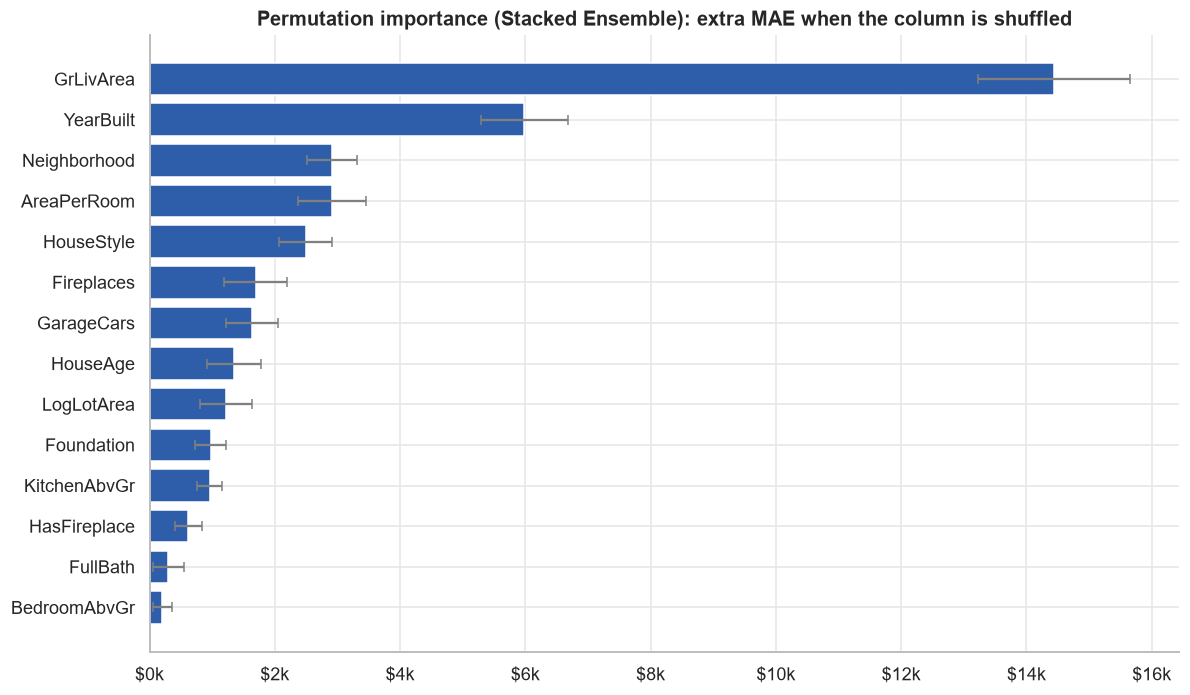

In [28]:
perm = permutation_importance(final_models[BEST], X_test, y_test, n_repeats=15, random_state=SEED,
                              scoring='neg_mean_absolute_error', n_jobs=-1)
imp = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                   index=X_test.columns).sort_values('mean').tail(14)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(imp.index, imp['mean'], xerr=imp['std'], color=PALETTE[0], ecolor='grey', capsize=3)
ax.xaxis.set_major_formatter(usd)
ax.set_title(f'Permutation importance ({BEST}): extra MAE when the column is shuffled')
plt.tight_layout(); plt.show()

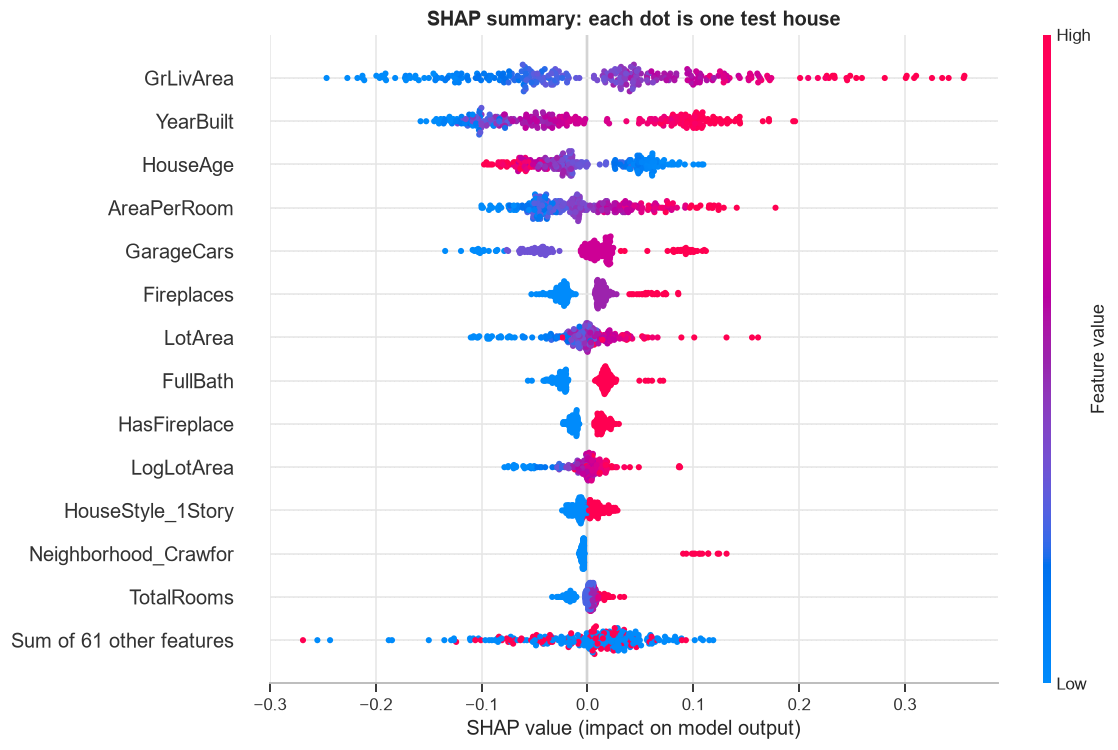

In [29]:
lgbm_pipe = tuned['LightGBM'].regressor_
prep, booster = lgbm_pipe.named_steps['prep'], lgbm_pipe.named_steps['model']
X_test_t = pd.DataFrame(prep.transform(X_test), columns=[n.split('__', 1)[1] for n in prep.get_feature_names_out()])

explainer = shap.TreeExplainer(booster)
shap_values = explainer(X_test_t)

shap.plots.beeswarm(shap_values, max_display=14, show=False, plot_size=(11, 7))
plt.title('SHAP summary: each dot is one test house', fontweight='bold')
plt.tight_layout(); plt.show()

SHAP is computed for the tuned LightGBM, one of the ensemble's members, because exact SHAP values for tree
models are fast to compute.

**Reading the SHAP chart:** each row is a feature, each dot a house. Dots to the right pushed that
house's price *up*, to the left pushed it *down*. Red means a high feature value, blue a low one.
So red dots on the right for `GrLivArea` mean: big living area, higher price. The values are in
log(price) units, so +0.1 means roughly +10% on the price.

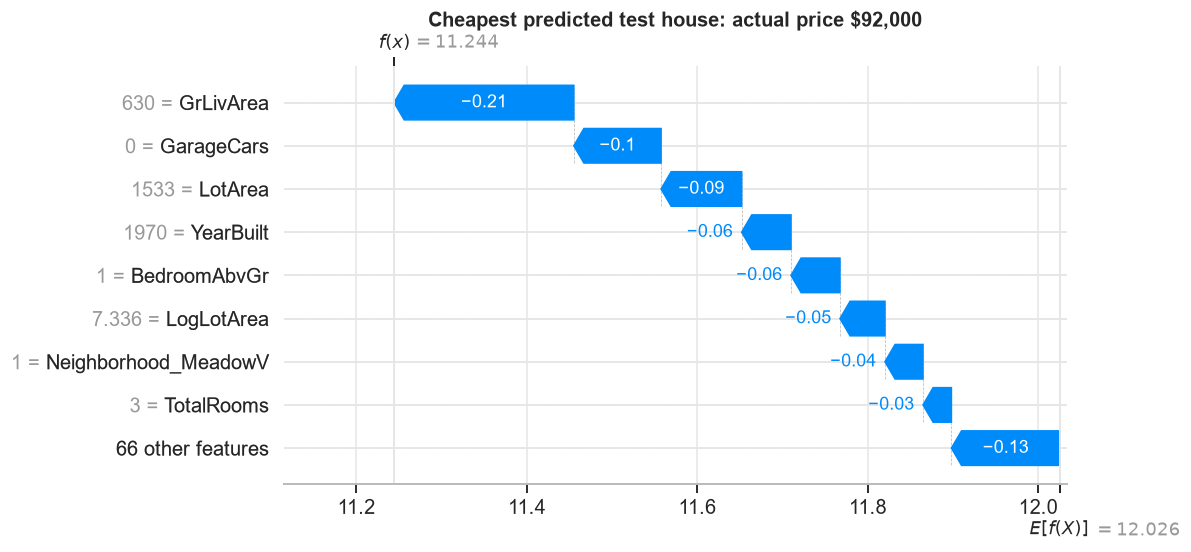

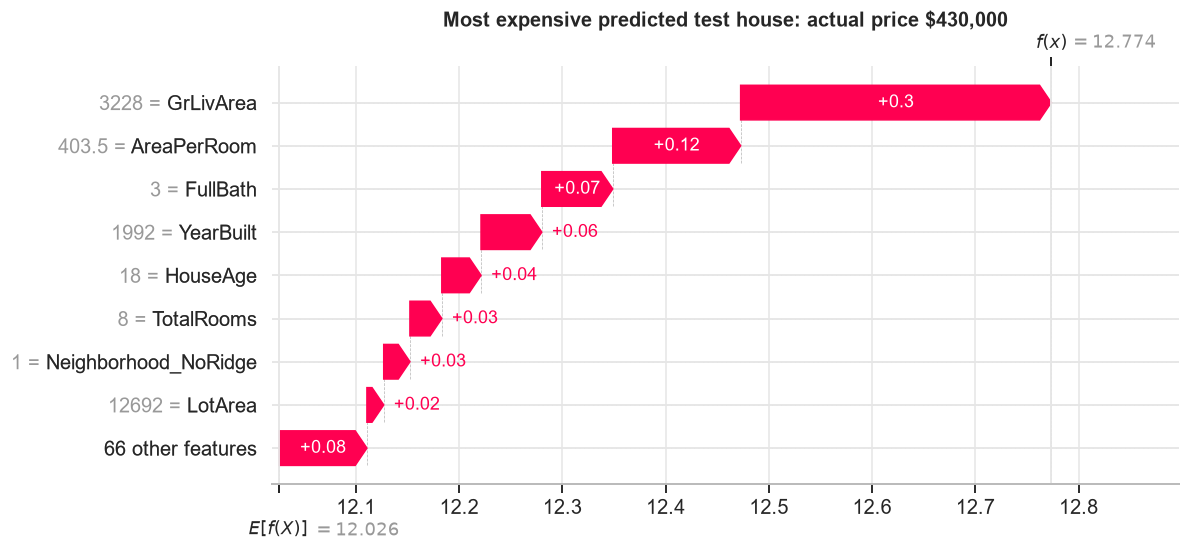

In [30]:
i_exp = int(np.argmax(best_pred))
i_cheap = int(np.argmin(best_pred))
for i, title in [(i_cheap, 'Cheapest predicted test house'), (i_exp, 'Most expensive predicted test house')]:
    shap.plots.waterfall(shap_values[i], max_display=9, show=False)
    plt.gcf().set_size_inches(11, 5.2)
    plt.title(f'{title}: actual price ${y_test.iloc[i]:,.0f}', fontweight='bold', pad=26)
    plt.tight_layout(); plt.show()

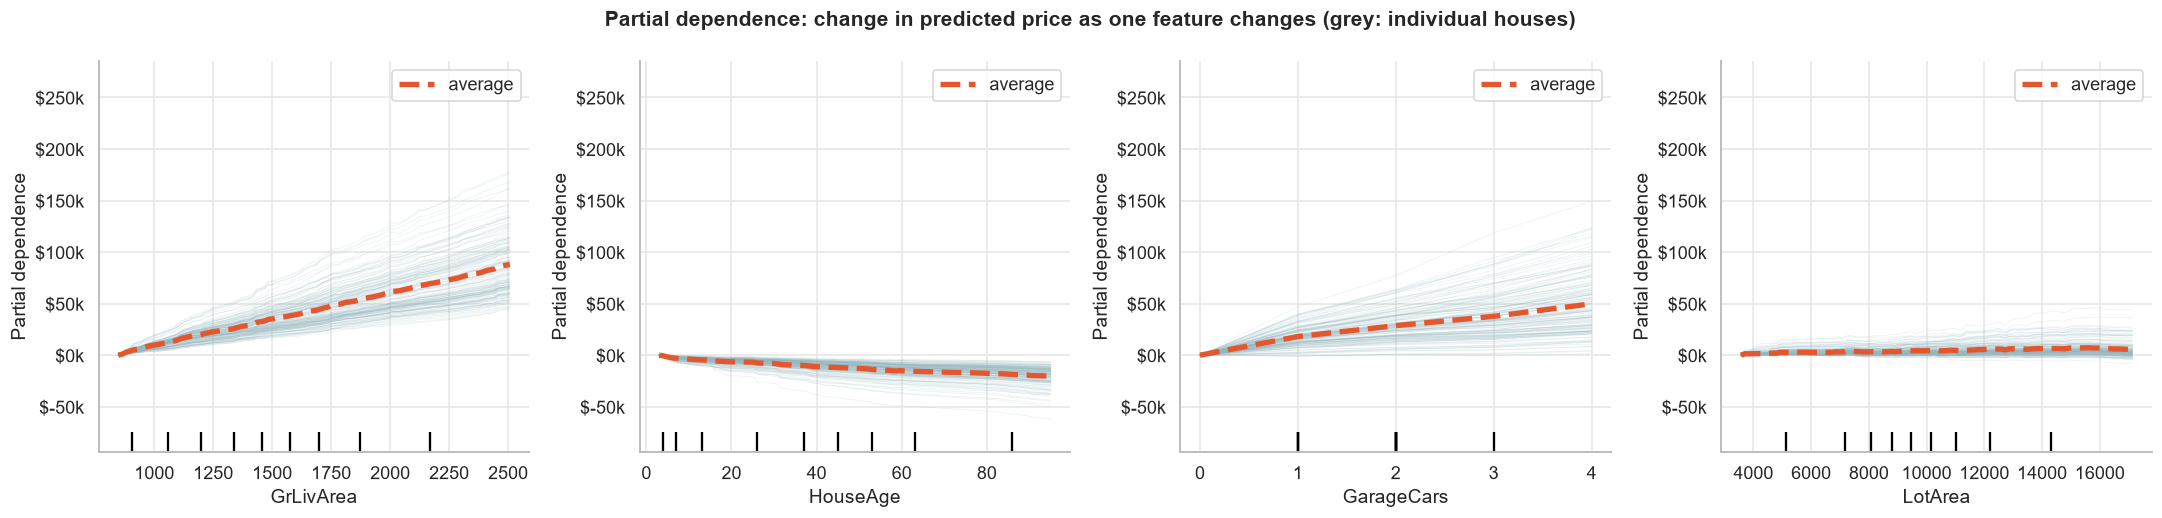

In [31]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
PartialDependenceDisplay.from_estimator(
    final_models[BEST], X_train, ['GrLivArea', 'HouseAge', 'GarageCars', 'LotArea'],
    ax=ax, kind='both', centered=True, subsample=150, random_state=SEED,
    ice_lines_kw={'color': PALETTE[10], 'alpha': 0.18}, pd_line_kw={'color': PALETTE[1], 'lw': 3.5})
for a in fig.axes:
    a.yaxis.set_major_formatter(usd)
fig.suptitle('Partial dependence: change in predicted price as one feature changes (grey: individual houses)',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 8. Insights, Price Estimator and Conclusion

### 8.1 A price range, not just a number

A single number hides uncertainty. We train two extra models that predict the **10th and 90th
percentile** of the price (quantile regression). On their own such ranges usually come out too narrow,
so we **calibrate them with conformal prediction**: on held-out folds we measure how far real prices
fall outside the range, and widen it by exactly that much. The result is a range that holds about 80%
of real prices on new data, which we check on the test set.

Raw quantile range holds 72% of test prices; after conformal calibration: 80%.


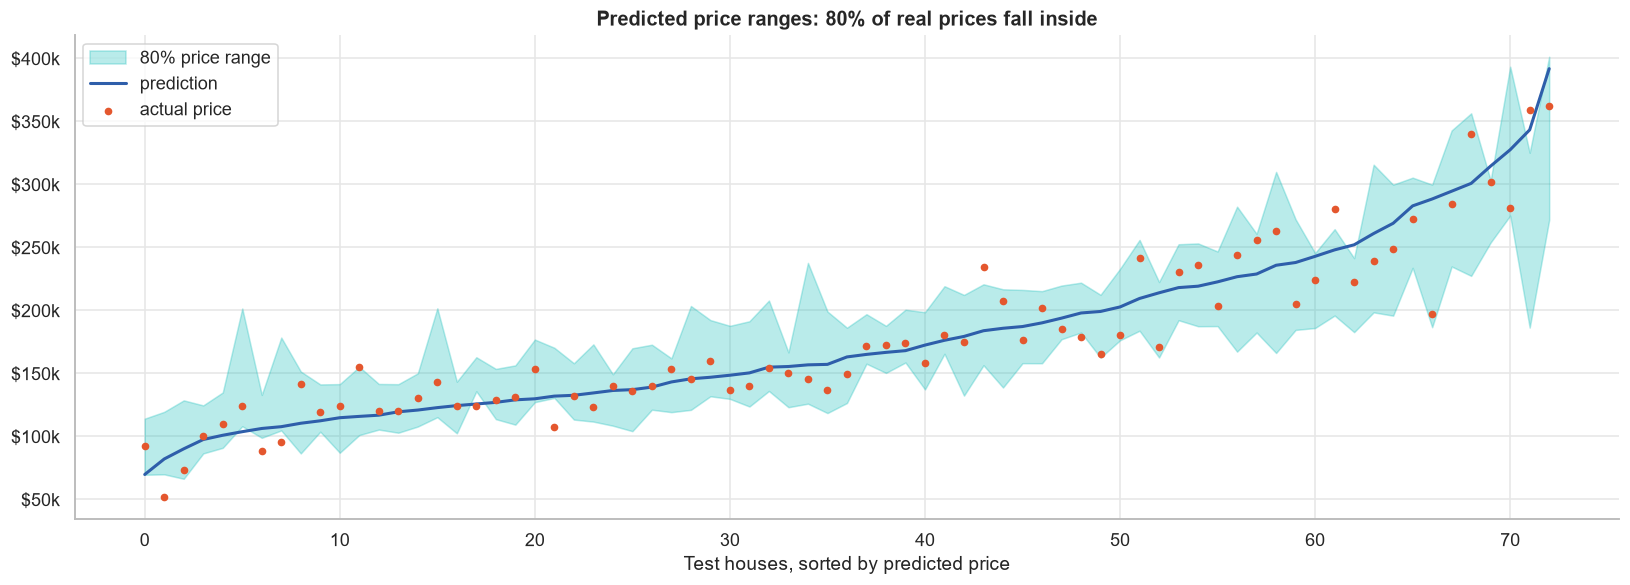

In [32]:
def quantile_model(alpha):
    return make_model(GradientBoostingRegressor(loss='quantile', alpha=alpha, n_estimators=500,
                                                learning_rate=0.03, max_depth=3, random_state=SEED),
                      scale=False)

low_model, high_model = quantile_model(0.10), quantile_model(0.90)

lo_oof = cross_val_predict(low_model, X_train, y_train, cv=CV, n_jobs=-1)
hi_oof = cross_val_predict(high_model, X_train, y_train, cv=CV, n_jobs=-1)
ly = np.log(y_train)
conf_scores = np.maximum(np.log(lo_oof) - ly, ly - np.log(hi_oof))
n = len(conf_scores)
q_adj = np.quantile(conf_scores, min(1.0, np.ceil((n + 1) * 0.8) / n))
low_model.fit(X_train, y_train); high_model.fit(X_train, y_train)


def price_range(X):
    return low_model.predict(X) * np.exp(-q_adj), high_model.predict(X) * np.exp(q_adj)


raw_cov = ((y_test >= low_model.predict(X_test)) & (y_test <= high_model.predict(X_test))).mean()
low, high = price_range(X_test)
coverage = ((y_test >= low) & (y_test <= high)).mean()
print(f'Raw quantile range holds {raw_cov:.0%} of test prices; after conformal calibration: {coverage:.0%}.')

order_ = np.argsort(best_pred)[::4]
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.fill_between(range(len(order_)), low[order_], high[order_], color=PALETTE[2], alpha=0.3,
                label='80% price range')
ax.plot(best_pred[order_], color=PALETTE[0], lw=2, label='prediction')
ax.scatter(range(len(order_)), y_test.values[order_], s=16, color=PALETTE[1], zorder=3, label='actual price')
ax.yaxis.set_major_formatter(usd)
ax.set_xlabel('Test houses, sorted by predicted price')
ax.set_title(f'Predicted price ranges: {coverage:.0%} of real prices fall inside')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### 8.2 Where does the money go? Neighbourhood value map

Average price tells only half the story; a big house in a cheap area can still cost a lot. Below, each
bubble is a neighbourhood: how expensive it is, how big its houses are, and how many sales it had.

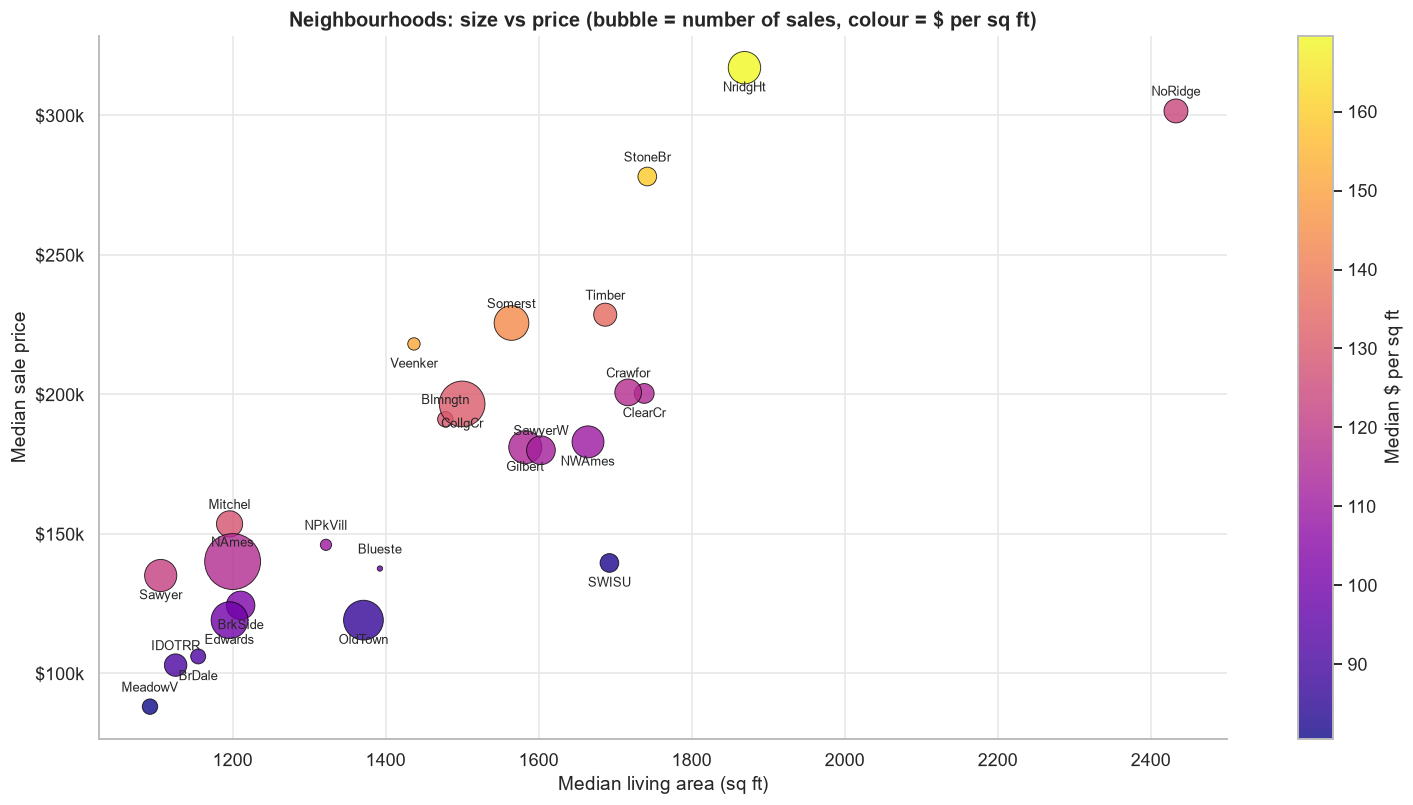

In [33]:
hood = housing.groupby('Neighborhood').agg(price=('SalePrice', 'median'), area=('GrLivArea', 'median'),
                                           sales=('SalePrice', 'size'))
hood['price_per_sqft'] = hood['price'] / hood['area']

fig, ax = plt.subplots(figsize=(14, 7.5))
sc = ax.scatter(hood['area'], hood['price'], s=hood['sales'] * 6, c=hood['price_per_sqft'],
                cmap='plasma', alpha=0.8, edgecolor='black', linewidth=0.6)
for k, (n, r) in enumerate(hood.sort_values('area').iterrows()):
    up = k % 2 == 0
    ax.annotate(n, (r['area'], r['price']), fontsize=8.5, ha='center', va='bottom' if up else 'top',
                xytext=(0, 8 if up else -9), textcoords='offset points')
ax.yaxis.set_major_formatter(usd)
ax.set_xlabel('Median living area (sq ft)'); ax.set_ylabel('Median sale price')
ax.set_title('Neighbourhoods: size vs price (bubble = number of sales, colour = $ per sq ft)')
plt.colorbar(sc, label='Median $ per sq ft')
plt.tight_layout(); plt.show()

### 8.3 Finding good deals

Using **cross-validated predictions** (each house is priced by a model that never saw it), we can flag
houses that sold well *below* what the model expected. For a buyer or investor these are the listings
worth a second look.

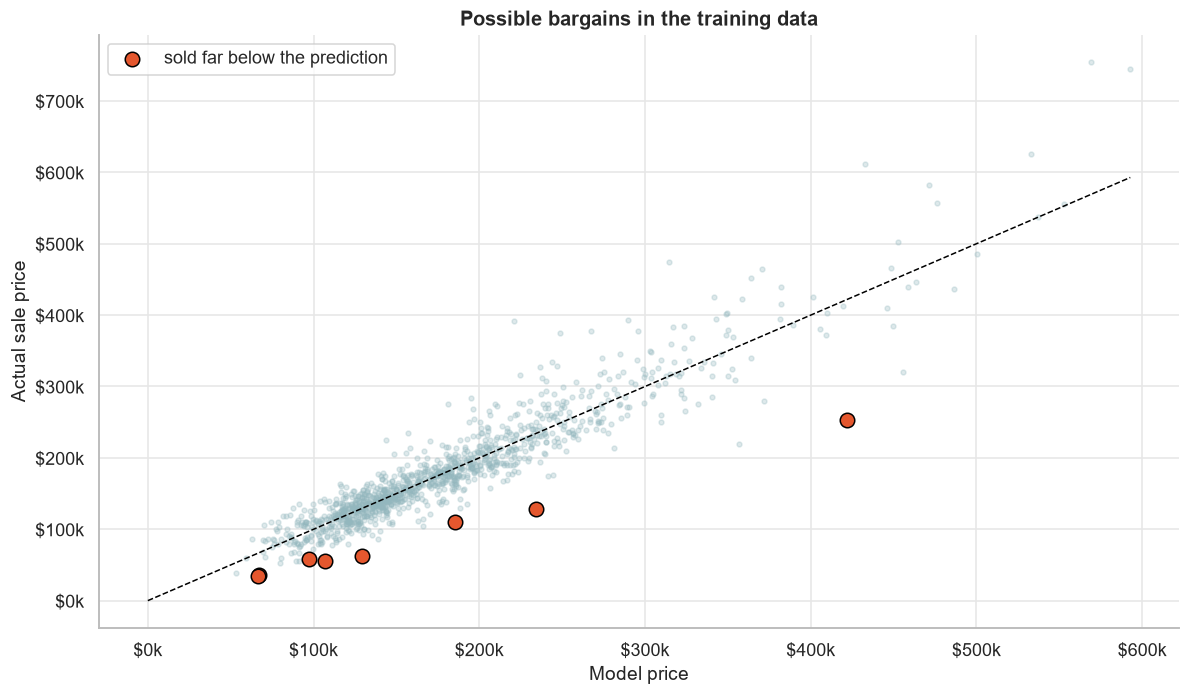

,Neighborhood,GrLivArea,YearBuilt,SaleCondition,Actual,Predicted,Below model by
461,Sawyer,864,1965,Normal,"$62,383","$129,310",52%
810,IDOTRR,"1,044",1952,Alloca,"$55,993","$106,852",48%
914,IDOTRR,480,1949,Abnorml,"$35,311","$67,188",47%
494,IDOTRR,720,1920,Abnorml,"$34,900","$66,237",47%
664,NAmes,"2,380",1965,Abnorml,"$129,000","$234,249",45%
660,NAmes,"1,392",1968,Normal,"$110,000","$185,545",41%
579,NridgHt,"2,042",2008,Partial,"$253,293","$422,170",40%
1377,Edwards,864,1914,Normal,"$58,500","$97,460",40%


In [34]:
oof = cross_val_predict(tuned['LightGBM'], X_train, y_train, cv=CV, n_jobs=-1)
deals = X_train.assign(Actual=y_train, Predicted=oof)
deals['Below model by'] = 1 - deals['Actual'] / deals['Predicted']
top_deals = deals.sort_values('Below model by', ascending=False).head(8)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(deals['Predicted'], deals['Actual'], s=10, alpha=0.3, color=PALETTE[10])
ax.scatter(top_deals['Predicted'], top_deals['Actual'], s=90, color=PALETTE[1], edgecolor='black',
           label='sold far below the prediction')
m = deals['Predicted'].max()
ax.plot([0, m], [0, m], 'k--', lw=1)
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd)
ax.set_xlabel('Model price'); ax.set_ylabel('Actual sale price')
ax.set_title('Possible bargains in the training data')
ax.legend()
plt.tight_layout(); plt.show()

(top_deals[['Neighborhood', 'GrLivArea', 'YearBuilt', 'SaleCondition', 'Actual', 'Predicted', 'Below model by']]
    .style.format({'Actual': '${:,.0f}', 'Predicted': '${:,.0f}', 'Below model by': '{:.0%}',
                   'GrLivArea': '{:,.0f}', 'YearBuilt': '{:.0f}'}))

**Note:** five of these eight "bargains" were not ordinary sales: `Abnorml` (foreclosures and short
sales), `Alloca` (allocations) and `Partial` (a new home sold before it was finished). Such sales often go
below market value for reasons that have nothing to do with the house, a pattern a human valuer knows too.
The rest are the interesting ones: ordinary sales the model thinks were underpriced.

### 8.4 What-if simulator

Take one typical house and change a single thing. How much is an extra 500 sq ft worth? A garage space?

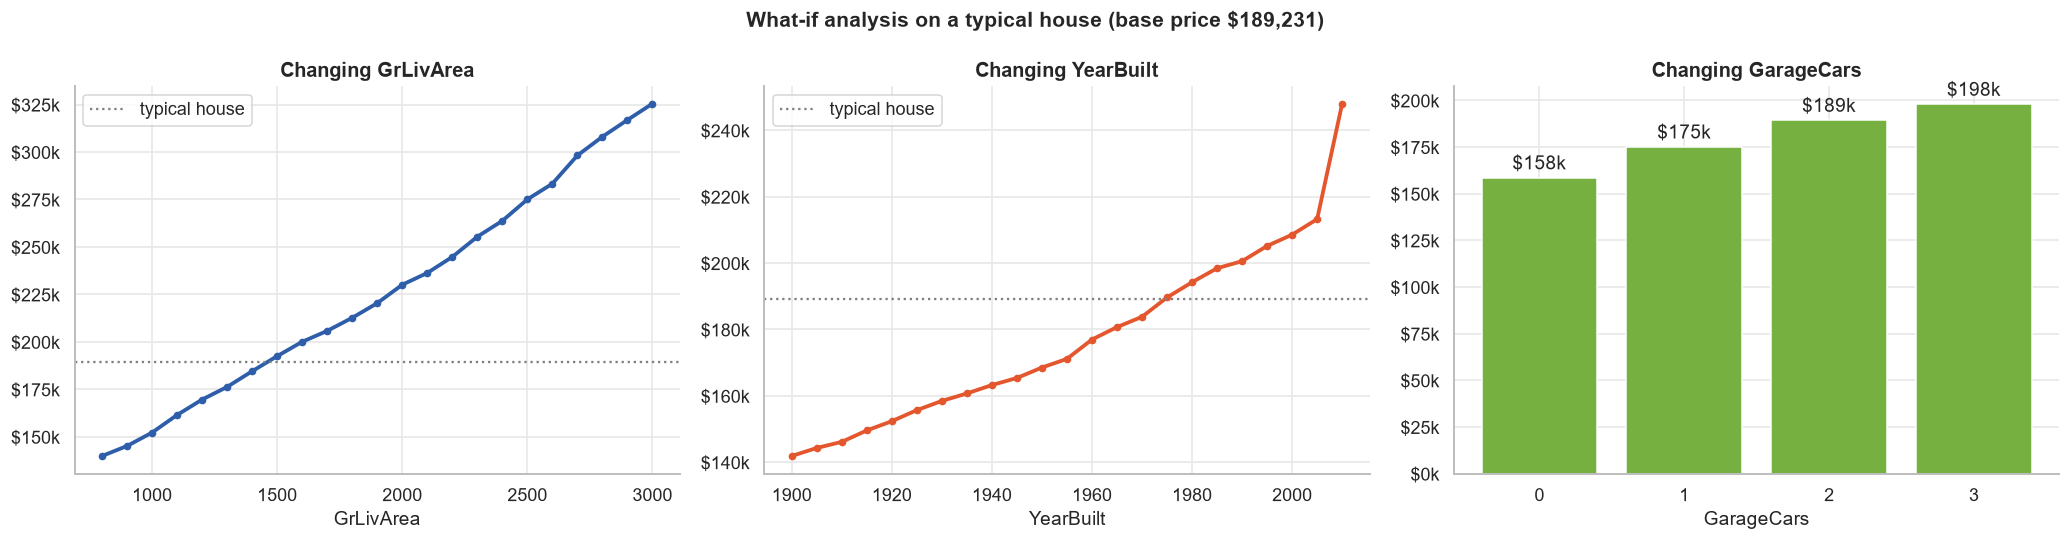

In [35]:
typical = X_train.mode().iloc[[0]].copy()
for c in num_features:
    typical[c] = X_train[c].median()
typical = add_features(typical.drop(columns=['HouseAge', 'TotalRooms', 'AreaPerRoom', 'HasGarage',
                                             'HasFireplace', 'LogLotArea']))[X_train.columns]
predict = final_models[BEST].predict
base_price = predict(typical)[0]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, col, values, color in [(axes[0], 'GrLivArea', np.arange(800, 3001, 100), PALETTE[0]),
                               (axes[1], 'YearBuilt', np.arange(1900, 2011, 5), PALETTE[1]),
                               (axes[2], 'GarageCars', [0, 1, 2, 3], PALETTE[4])]:
    rows = pd.concat([typical.assign(**{col: v}) for v in values])
    rows = add_features(rows.drop(columns=['HouseAge', 'TotalRooms', 'AreaPerRoom', 'HasGarage',
                                           'HasFireplace', 'LogLotArea']))[X_train.columns]
    prices = predict(rows)
    if col == 'GarageCars':
        bars = ax.bar([str(v) for v in values], prices, color=color)
        ax.bar_label(bars, labels=[f'${p/1000:,.0f}k' for p in prices], padding=3)
    else:
        ax.plot(values, prices, color=color, lw=2.5, marker='o', markersize=4)
        ax.axhline(base_price, color='grey', ls=':', label='typical house')
        ax.legend()
    ax.yaxis.set_major_formatter(usd)
    ax.set_title(f'Changing {col}'); ax.set_xlabel(col)
fig.suptitle(f'What-if analysis on a typical house (base price ${base_price:,.0f})', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 8.5 Try it: the price estimator

The final model wrapped in one function. Describe a house and get a price with a range.

In [36]:
def estimate_price(**house):
    row = typical.copy()
    for k, v in house.items():
        row[k] = v
    row = add_features(row.drop(columns=['HouseAge', 'TotalRooms', 'AreaPerRoom', 'HasGarage',
                                         'HasFireplace', 'LogLotArea']))[X_train.columns]
    price = predict(row)[0]
    lo, hi = (v[0] for v in price_range(row))
    lo, hi = min(lo, price), max(hi, price)
    return price, lo, hi


examples = {
    'Starter home in Old Town': dict(Neighborhood='OldTown', GrLivArea=1000, YearBuilt=1925,
                                     BedroomAbvGr=2, FullBath=1, GarageCars=1, Fireplaces=0),
    'Family home in College Creek': dict(Neighborhood='CollgCr', GrLivArea=1800, YearBuilt=2003,
                                         BedroomAbvGr=3, FullBath=2, GarageCars=2, Fireplaces=1),
    'Large new house in Northridge Heights': dict(Neighborhood='NridgHt', GrLivArea=2600, YearBuilt=2008,
                                                   BedroomAbvGr=4, FullBath=3, GarageCars=3, Fireplaces=1,
                                                   SaleCondition='Partial', Foundation='PConc'),
}
for name, spec in examples.items():
    price, lo, hi = estimate_price(**spec)
    print(f'{name:40s} ${price:>9,.0f}   (likely ${lo:,.0f} to ${hi:,.0f})')

Starter home in Old Town                 $  110,644   (likely $85,214 to $132,400)
Family home in College Creek             $  244,603   (likely $194,014 to $251,423)


Large new house in Northridge Heights    $  430,673   (likely $291,899 to $430,673)


### 8.6 Summary

In [37]:
b = test_results.loc[BEST]
card = pd.DataFrame({
    'Item': ['Houses used', 'Features', 'Models compared', 'Best model', 'Test MAE', 'Test MAPE',
             'Test R²', 'Within 10% of the real price', '80% price range coverage'],
    'Value': [f'{len(housing):,}', f'{X_train.shape[1]} ({len(num_features)} numeric, {len(cat_features)} text)',
              f'{len(models)} plus a stacked ensemble', BEST, f'${b.MAE:,.0f}', f"{b['MAPE %']:.2f}%",
              f'{b.R2:.4f}', f'{within[1]:.0f}% of test houses', f'{coverage:.0%} of test houses'],
}).set_index('Item')
card

,Value
Item,
Houses used,"1,457"
Features,"21 (14 numeric, 7 text)"
Models compared,13 plus a stacked ensemble
Best model,Stacked Ensemble
Test MAE,"$19,037"
Test MAPE,12.52%
Test R²,0.8528
Within 10% of the real price,60% of test houses
80% price range coverage,80% of test houses


### 8.7 Conclusion

* **What worked:** predicting log(price), leak-free pipelines, tuning, a properly scaled neural network,
  and stacking five different kinds of models. On houses it has never seen, the final model explains about 85% of
  the price variation, is off by about 12% on average, and prices 6 in 10 houses within 10%, from only
  19 basic columns.
* **Honest uncertainty:** every estimate comes with a calibrated range that holds the real price 80% of
  the time.
* **What drives price:** living area matters most, then age, neighbourhood and space per room, then
  fireplaces and garage. That matches what a human valuer would say, and SHAP shows it for every house.
* **How it can be used:** quick first valuations for agents, spotting below-market listings for
  buyers, checking a mortgage's collateral value, and testing renovation ideas with the what-if tool.

**Limits to keep in mind**

| Limit | Why it matters |
|---|---|
| One city, sales from 2006 to 2010 | Prices and tastes change; retrain on local, recent sales before real use |
| Only 19 columns | No basement, quality rating or renovation data, which the full Kaggle set has |
| Luxury and unusual sales | Few examples, so the error and the price range are wider at the top end |
| Abnormal and family sales | Follow different rules than open market sales |

---
*CSE422: Artificial Intelligence, BRAC University. Faiaz Abrar Zaman Pronoy, Sinthia Khandoker and Md. Jahirul Islam Zishan.*